# Online vs. offline ripple comparison — laser-first-pulse matching

**Question 1: What happens online when Kay detects an offline ripple?** For every offline ripple `[start_time, end_time]`, check whether the **first pulse of at least one actual laser train** is inside the interval, with inclusive boundaries. Offline **TP** = at least one first laser pulse within the offline ripple; offline **FN** = none. Even when multiple laser trains begin within one ripple, that ripple contributes only one TP.

**Question 2: What is offline Kay doing when a laser train starts?** For every laser train, match its **first pulse** against *any* offline ripple interval. Mark trains as `TP` (offline-matched) or `FP-like` (online-only / unmatched). A laser train overlapping a ripple only through its later pulses **does not count** as a match.

The H5 `rip_detected` signal is retained **only as a diagnostic**, along with the H5 continuous online z-score. A laser-negative offline ripple is a *missed stimulation* under this definition, **not** automatically an online-detector failure: a detection may be blocked from stimulating by the lockout or other stimulation rules.

**Data provenance:** NWB supplies measured laser pulses; Spyglass `RippleTimesV1` supplies the offline ripple intervals and Kay filtered LFP inputs; the online H5 supplies the continuous online trace/detection flag. **Before running, verify that all files and the Spyglass ripple group refer to the intended animal, session, channels, and timebase** in the Setup cells. The source NWB / H5 / Spyglass files are not included in this notebook; results must be recomputed in your UCSF environment using **Restart Kernel & Run All**. Old outputs are intentionally cleared to avoid displaying stale H5-labeled results.


## Setup 1 — imports and file paths

In [1]:
import os
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py
import pynwb
import datajoint as dj
from scipy.stats import zscore

# Existing paths from your original notebook — edit if files moved.
NWB_PATH = Path('/stelmo/nwb/raw/Marcus20260801_.nwb')
H5_PATH = Path('/home/sgao/Downloads/20260801-131533_fsgui_log.h5')
DJ_CONFIG_PATH = Path('/home/sgao/source/spyglass/notebooks/dj_local_conf.json')
H5_RIPPLE_GROUP = '35386686-d04e-11ee-90c5-a0369f6f691e'
SESSION = '09_s5'
SESSION_EPOCH_INDEX = 8
N_PULSES_PER_TRAIN = 20
ONLINE_Z_THRESHOLD = 1.5
KAY_Z_THRESHOLD = 2.0
nwb_file_name = NWB_PATH.name

for p in (NWB_PATH, H5_PATH, DJ_CONFIG_PATH):
    if not p.exists():
        raise FileNotFoundError(f'Required file missing: {p}. Update the path above.')

dj.config.load(str(DJ_CONFIG_PATH))
import spyglass.ripple.v1 as sgrip
warnings.simplefilter('ignore', category=DeprecationWarning)
print('NWB:', NWB_PATH, '| H5:', H5_PATH, '| session:', SESSION)

/home/sgao/source/miniforge3/envs/spyglass/lib/python3.10/site-packages/datajoint/plugin.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
[2026-10-16 15:47:54,269][INFO]: DataJoint is configured from /home/sgao/source/spyglass/notebooks/dj_local_conf.json
[2026-10-16 15:47:58,652][INFO]: DataJoint 0.14.5 connected to sgao@lmf-db.cin.ucsf.edu:3306


NWB: /stelmo/nwb/raw/Marcus20260801_.nwb | H5: /home/sgao/Downloads/20260801-131533_fsgui_log.h5 | session: 09_s5


## Setup 2 — NWB epoch and actual laser pulse timestamps

First laser pulse of each 20-pulse train is the **only** online event time used for TP/FN matching. Verify the number of pulses per train and the recording's train structure before interpreting the result.

In [2]:
# Keep the NWB reader open so its lazy datasets remain valid.
io = pynwb.NWBHDF5IO(str(NWB_PATH), mode='r')
nwbf = io.read()
epochs_df = nwbf.intervals['epochs'].to_dataframe()
if SESSION_EPOCH_INDEX >= len(epochs_df):
    raise IndexError(f'Epoch {SESSION_EPOCH_INDEX} missing; inspect epochs_df.')
epoch_row = epochs_df.iloc[SESSION_EPOCH_INDEX]
epoch_start = float(epoch_row['start_time'])
epoch_stop = float(epoch_row['stop_time'])

laser = nwbf.processing['behavior'].data_interfaces['behavioral_events'].time_series['Laser']
laser_data = np.asarray(laser.data[:]).reshape(-1)
laser_timestamps = np.asarray(laser.timestamps[:], dtype=float)
if len(laser_data) != len(laser_timestamps):
    raise ValueError('Laser data and timestamp length mismatch')

laser_mask = (laser_timestamps >= epoch_start) & (laser_timestamps <= epoch_stop)
laser_session = laser_data[laser_mask]
laser_times_session = laser_timestamps[laser_mask]
# Each 0->1 change in the recorded laser signal is one pulse onset.
rising_edges = np.diff((laser_session > 0).astype(int)) == 1
pulse_start_times = laser_times_session[1:][rising_edges]
if len(laser_session) and laser_session[0] > 0:
    print('WARNING: Laser high at session start; a boundary pulse may be truncated.')

# The original acquisition delivered N_PULSES_PER_TRAIN pulses per train.
# Keep the same segmentation, but check it has no leftovers / obvious mis-grouping.
n_complete_trains, n_remaining_pulses = divmod(len(pulse_start_times), N_PULSES_PER_TRAIN)
if n_remaining_pulses:
    raise ValueError(
        f'{n_remaining_pulses} leftover laser pulses after dividing into '
        f'{N_PULSES_PER_TRAIN}-pulse trains. Train first-pulse times cannot be '
        'trusted until the incomplete/boundary train is investigated.'
    )
if n_complete_trains == 0:
    raise ValueError('No complete laser trains in selected epoch.')
online_trains = pulse_start_times.reshape(-1, N_PULSES_PER_TRAIN)
laser_onsets = online_trains[:, 0].astype(float)  # ACTUAL first-pulse timestamps
online_starts = laser_onsets.copy()
online_ends = online_trains[:, -1].astype(float)
assert np.all(np.diff(laser_onsets) > 0), 'Laser train start times not strictly increasing'

# QC: compare within-train and between-train gaps to detect a shifted grouping.
if N_PULSES_PER_TRAIN > 1:
    within_gap = np.diff(online_trains, axis=1).ravel()
    between_gap = online_trains[1:, 0] - online_trains[:-1, -1]
    print('Median within-train pulse gap (ms):', round(np.median(within_gap)*1000, 2))
    if len(between_gap):
        print('Median between-train gap (ms):', round(np.median(between_gap)*1000, 2))
        if np.min(between_gap) <= np.median(within_gap):
            warnings.warn('Some between-train gaps are no larger than typical pulse gaps. Verify train grouping.')

print(f'Epoch {SESSION}: {epoch_start:.6f}–{epoch_stop:.6f} | '
      f'pulse starts={len(pulse_start_times)} | complete trains={len(online_trains)}')
print('First train onsets (actual laser timestamp, s):', laser_onsets[:5])

Median within-train pulse gap (ms): 5.0
Median between-train gap (ms): 677.17
Epoch 09_s5: 1785620822.841000–1785623226.553449 | pulse starts=35640 | complete trains=1782
First train onsets (actual laser timestamp, s): [1.78562082e+09 1.78562083e+09 1.78562083e+09 1.78562083e+09
 1.78562083e+09]


## Setup 3 — load continuous online detector H5 trace

In [3]:
with h5py.File(H5_PATH, 'r') as f:
    if H5_RIPPLE_GROUP not in f:
        raise KeyError(f'H5 group {H5_RIPPLE_GROUP} not found; available groups: {list(f.keys())}')
    g = f[H5_RIPPLE_GROUP]
    required = ['rip_timestamp', 'rip_envelope', 'rip_mean', 'rip_sd', 'rip_detected']
    missing = [k for k in required if k not in g]
    if missing:
        raise KeyError(f'Missing H5 datasets: {missing}; present: {list(g.keys())}')
    online_df = pd.DataFrame({
        'timestamp_ns': g['rip_timestamp'][:],
        'envelope': g['rip_envelope'][:],
        'mean': g['rip_mean'][:],
        'sd': g['rip_sd'][:],
        'detected': g['rip_detected'][:],
    })
    for optional in ['rip_mean_threshold', 'rip_sd_threshold']:
        if optional in g:
            online_df[optional.replace('rip_', '')] = g[optional][:]
online_df['timestamp'] = online_df['timestamp_ns'] / 1e9
online_df['z'] = np.divide(
    online_df['envelope'] - online_df['mean'], online_df['sd'],
    out=np.full(len(online_df), np.nan, dtype=float),
    where=online_df['sd'].to_numpy() != 0)
online_df = online_df.sort_values('timestamp').reset_index(drop=True)
online = online_df.copy()
online_overlap = online_df.loc[online_df['timestamp'].between(epoch_start, epoch_stop)].copy()
if online_overlap.empty:
    raise ValueError('No online H5 samples overlap the chosen NWB epoch. Check timestamp units and file dates.')
print(f'Online samples (epoch): {len(online_overlap):,}; H5 span {online_overlap.timestamp.min():.6f}–{online_overlap.timestamp.max():.6f}')

Online samples (epoch): 3,605,534; H5 span 1785620822.841029–1785623226.552859


## Setup 4 — offline Kay intervals versus first pulse of each real laser train (canonical TP/FN)

This is the **only** place where the offline `event_type` labels are defined. We preserve H5 event onsets in separately named columns for later investigation of laser-negative / lockout-affected offline ripples.

In [4]:
# IMPORTANT: verify this Spyglass key refers to the intended OFFLINE ripple file/group.
base_query = sgrip.RippleTimesV1() & {
    'nwb_file_name': nwb_file_name,
    'target_interval_list_name': SESSION,
    'ripple_param_name': 'default_trodes',
}
if len(base_query) == 0:
    raise LookupError(f'No RippleTimesV1 records for {nwb_file_name}, {SESSION}, default_trodes')
available_keys = base_query.fetch('KEY')
preferred = ['Ripple Detection Channels', 'ripple detection channels']
selected = next((k for label in preferred for k in available_keys if k.get('group_name') == label), None)
if selected is None:
    raise LookupError(f'Ripple detection group not found; available groups: {[k.get("group_name") for k in available_keys]}')
key = selected
print('CONFIRM this is the CORRECT offline ripple source:', key)
offline_s5 = (sgrip.RippleTimesV1() & key).fetch1_dataframe().sort_values('start_time').copy()
for col in ('start_time', 'end_time', 'max_zscore'):
    if col not in offline_s5.columns:
        raise KeyError(f'Offline ripple table missing {col}: {offline_s5.columns.tolist()}')
if offline_s5.empty:
    raise ValueError('No offline ripples for chosen session')
if offline_s5.index.has_duplicates:
    raise ValueError('Offline ripple row index is not unique; reset or assign unique offline IDs first.')

# Keep the same source DataFrame for the existing downstream Kay / online z plots.
offline_ripples = offline_s5.copy()
offline_starts = offline_s5['start_time'].to_numpy(dtype=float)
offline_ends = offline_s5['end_time'].to_numpy(dtype=float)
if not np.all(np.isfinite(offline_starts) & np.isfinite(offline_ends)):
    raise ValueError('Offline ripple times contain NaN/inf')
if np.any(offline_ends < offline_starts):
    raise ValueError('Offline ripple end before start')

# -------------------------------------------------------------------------
# 1. Offline-centered TP/FN: first laser pulse must fall INSIDE ripple.
# For a sorted list of first-pulse times, searchsorted counts every train
# start in the inclusive interval [offline_start, offline_end].
# -------------------------------------------------------------------------
laser_onsets = np.asarray(online_trains[:, 0], dtype=float)
laser_left = np.searchsorted(laser_onsets, offline_starts, side='left')
laser_right = np.searchsorted(laser_onsets, offline_ends, side='right')
offline_laser_counts = laser_right - laser_left
has_laser = offline_laser_counts > 0
first_laser_onset = np.full(len(offline_s5), np.nan)
first_laser_onset[has_laser] = laser_onsets[laser_left[has_laser]]

offline_event_table = offline_s5.copy()
offline_event_table['n_laser_onsets'] = offline_laser_counts
offline_event_table['first_laser_onset'] = first_laser_onset
offline_event_table['has_laser'] = has_laser
offline_event_table['event_type'] = np.where(has_laser, 'TP', 'FN')
offline_event_table['match_type'] = offline_event_table['event_type']
clean_tp = offline_event_table.loc[offline_event_table.event_type == 'TP'].copy()
fn = offline_event_table.loc[offline_event_table.event_type == 'FN'].copy()

# -------------------------------------------------------------------------
# 2. Laser-centered classification: did THIS train start during ANY ripple?
# The prefix-max approach also handles overlapping/nested offline intervals.
# -------------------------------------------------------------------------
latest_start_pos = np.searchsorted(offline_starts, laser_onsets, side='right') - 1
best_end_pos = np.zeros(len(offline_s5), dtype=int)
for i in range(1, len(best_end_pos)):
    best_end_pos[i] = i if offline_ends[i] > offline_ends[best_end_pos[i-1]] else best_end_pos[i-1]
laser_valid_candidate = latest_start_pos >= 0
laser_match_pos = np.full(len(laser_onsets), -1, dtype=int)
laser_match_pos[laser_valid_candidate] = best_end_pos[latest_start_pos[laser_valid_candidate]]
laser_has_offline_match = np.zeros(len(laser_onsets), dtype=bool)
laser_has_offline_match[laser_valid_candidate] = (
    laser_onsets[laser_valid_candidate] <= offline_ends[laser_match_pos[laser_valid_candidate]]
)
laser_match_pos[~laser_has_offline_match] = -1
laser_match_ids = [offline_s5.index[p] if p >= 0 else None for p in laser_match_pos]
laser_event_table = pd.DataFrame({
    'laser_id': np.arange(len(laser_onsets)),
    'laser_onset': laser_onsets,
    'laser_train_end': online_trains[:, -1].astype(float),
    'matched_offline_id': pd.Series(laser_match_ids, dtype='object'),
    'has_offline_match': laser_has_offline_match,
    'event_type': np.where(laser_has_offline_match, 'TP', 'FP-like'),
})
laser_event_table['matching_rule'] = 'first laser pulse in offline ripple interval'
fp_like_laser_onsets = laser_onsets[~laser_has_offline_match]
fp_indices = np.flatnonzero(~laser_has_offline_match)

# Cross-check both directions use the SAME event-level matching definition.
assert np.all(has_laser == np.array([
    np.any((laser_onsets >= start) & (laser_onsets <= end))
    for start, end in zip(offline_starts, offline_ends)
]))
assert np.array_equal(laser_has_offline_match, np.array([
    np.any((offline_starts <= t) & (offline_ends >= t)) for t in laser_onsets
]))

# -------------------------------------------------------------------------
# 3. H5 `rip_detected` ONSETS — diagnostic only, NEVER used for TP/FN.
# -------------------------------------------------------------------------
det_values = online_overlap['detected'].to_numpy()
if not np.all(np.isfinite(det_values)) or not np.all(np.isin(np.unique(det_values), [0, 1])):
    raise ValueError('rip_detected must be 0/1 with no NaNs')
detected = det_values.astype(bool)
online_times = online_overlap['timestamp'].to_numpy(dtype=float)
if np.any(np.diff(online_times) < 0):
    raise ValueError('H5 times not sorted')
detection_onset_indices = np.flatnonzero(detected & ~np.r_[False, detected[:-1]])
detection_offset_indices = np.flatnonzero(detected & ~np.r_[detected[1:], False])
detection_onsets = online_times[detection_onset_indices]
detection_offsets = online_times[detection_offset_indices]
if len(detection_onset_indices) and detection_onset_indices[0] == 0:
    # No true onset observed if rip_detected was already true at epoch start.
    detection_onsets = detection_onsets[1:]
    detection_offsets = detection_offsets[1:]

h5_left = np.searchsorted(detection_onsets, offline_starts, side='left')
h5_right = np.searchsorted(detection_onsets, offline_ends, side='right')
offline_detection_counts = h5_right - h5_left
offline_event_table['n_h5_detection_onsets'] = offline_detection_counts
offline_event_table['has_h5_detection'] = offline_detection_counts > 0

h5_has_offline_match = np.array([
    np.any((offline_starts <= t) & (offline_ends >= t)) for t in detection_onsets
], dtype=bool)
detection_event_table = pd.DataFrame({
    'detection_id': np.arange(len(detection_onsets)),
    'onset_time': detection_onsets,
    'has_offline_match': h5_has_offline_match,
})
fp_like_detection_onsets = detection_onsets[~h5_has_offline_match]

print('Offline ripples:', len(offline_event_table),
      '| TP (laser first pulse within ripple):', len(clean_tp), '| FN:', len(fn))
print('Laser trains:', len(laser_event_table),
      '| matched:', int(laser_has_offline_match.sum()),
      '| online-only:', len(fp_like_laser_onsets))
print('Offline ripples with >1 train start:', int((offline_laser_counts > 1).sum()))
print('H5 detection onsets (diagnostic only):', len(detection_onsets))
print('\nLaser-defined offline outcome x H5 detector activity:')
print(pd.crosstab(offline_event_table['event_type'],
                  offline_event_table['has_h5_detection'],
                  rownames=['Laser-defined TP/FN'], colnames=['Any H5 detection onset']))
print('\nTrain matching:')
print(laser_event_table['event_type'].value_counts())


CONFIRM this is the CORRECT offline ripple source: {'lfp_merge_id': UUID('c4d490cf-a82b-7ac9-99c9-78344fc1dce9'), 'filter_name': 'Ripple 150-250 Hz', 'filter_sampling_rate': 1000, 'nwb_file_name': 'Marcus20260801_.nwb', 'target_interval_list_name': '09_s5', 'lfp_band_sampling_rate': 1000, 'group_name': 'Ripple Detection Channels', 'ripple_param_name': 'default_trodes', 'pos_merge_id': UUID('a9be6fdd-747e-6d4a-7ef3-bf7cf2dacc4d')}


/home/sgao/source/miniforge3/envs/spyglass/lib/python3.10/site-packages/hdmf/spec/namespace.py:620: UserWarning: Ignoring the following cached namespace(s) because another version is already loaded:
ndx-pose - cached version: 0.3.0, loaded version: 0.2.0
The loaded extension(s) may not be compatible with the cached extension(s) in the file. Please check the extension documentation and ignore this warning if these versions are compatible.
  self.warn_for_ignored_namespaces(ignored_namespaces)
/home/sgao/source/miniforge3/envs/spyglass/lib/python3.10/site-packages/hdmf/backends/hdf5/h5tools.py:620: BrokenLinkWarning: Path to Group altered/broken at /general/devices/MarketTech LuxX+ Red/model
  warnings.warn('Path to Group altered/broken at ' + os.path.join(h5obj.name, k), BrokenLinkWarning)
/home/sgao/source/miniforge3/envs/spyglass/lib/python3.10/site-packages/hdmf/backends/hdf5/h5tools.py:620: BrokenLinkWarning: Path to Group altered/broken at /general/devices/Optical fiber 1/model
  w

Offline ripples: 1737 | TP (laser first pulse within ripple): 671 | FN: 1066
Laser trains: 1782 | matched: 682 | online-only: 1100
Offline ripples with >1 train start: 11
H5 detection onsets (diagnostic only): 5546

Laser-defined offline outcome x H5 detector activity:
Any H5 detection onset  False  True 
Laser-defined TP/FN                 
FN                        916    150
TP                          1    670

Train matching:
event_type
FP-like    1100
TP          682
Name: count, dtype: int64


## Setup 5 — verify shared timebase and detector inputs

In [5]:
# Kay LFP inputs are computed by Spyglass in the first analysis cells below.
# Confirm data timebases BEFORE interpreting detector-vs-detector delays.
print('NWB epoch:', epoch_start, epoch_stop)
print('H5 time range:', online_overlap.timestamp.min(), online_overlap.timestamp.max())
print('Offline ripple range:', offline_starts.min(), offline_ends.max())
print('Laser pulse range:', (pulse_start_times.min(), pulse_start_times.max()) if len(pulse_start_times) else 'no pulses')
assert np.all(np.diff(online_overlap.timestamp.to_numpy()) >= 0)
assert np.all(offline_ends >= offline_starts)
if not np.any((offline_starts <= online_overlap.timestamp.max()) & (offline_ends >= online_overlap.timestamp.min())):
    raise ValueError('Offline ripple intervals do not overlap the online H5 recording.')
print('Timebase overlap checks passed. Differences in clock origins must still be verified experimentally.')

NWB epoch: 1785620822.841 1785623226.5534487
H5 time range: 1785620822.8410292 1785623226.5528588
Offline ripple range: 1785620828.813188 1785623218.9193301
Laser pulse range: (1785620824.6487496, 1785623226.2832983)
Timebase overlap checks passed. Differences in clock origins must still be verified experimentally.


---
## Analysis — all downstream offline TP/FN plots use **actual laser-first-pulse** labels

Online H5 **z-score** values are still analyzed as continuous predictors; H5 `rip_detected` is not used to assign labels. Unless a specific plot says otherwise, its TP/FN groups mean *laser-stimulated versus not laser-stimulated offline Kay ripples*.

In [6]:
# Same key used to load offline_s5 in Setup 4 (avoids group-name case mismatch).
speed, ripple_filtered_lfps, sampling_frequency = (
    sgrip.RippleTimesV1().get_ripple_lfps_and_position_info(key)
)

[2026-10-16 15:48:51,618][WARNING]: Skipped checksum for file with hash: a864e6a6-b84b-2674-2a7c-35a08a6c8191, and path: /stelmo/nwb/analysis/Marcus20260801/Marcus20260801_0K0OT3M9YF.nwb
[2026-10-16 15:48:51,622][WARNING]: Skipped checksum for file with hash: a864e6a6-b84b-2674-2a7c-35a08a6c8191, and path: /stelmo/nwb/analysis/Marcus20260801/Marcus20260801_0K0OT3M9YF.nwb
/home/sgao/source/miniforge3/envs/spyglass/lib/python3.10/site-packages/hdmf/backends/hdf5/h5tools.py:620: BrokenLinkWarning: Path to Group altered/broken at /general/devices/MarketTech LuxX+ Red/model
  warnings.warn('Path to Group altered/broken at ' + os.path.join(h5obj.name, k), BrokenLinkWarning)
/home/sgao/source/miniforge3/envs/spyglass/lib/python3.10/site-packages/hdmf/backends/hdf5/h5tools.py:620: BrokenLinkWarning: Path to Group altered/broken at /general/devices/Optical fiber 1/model
  warnings.warn('Path to Group altered/broken at ' + os.path.join(h5obj.name, k), BrokenLinkWarning)
/home/sgao/source/minifor

In [7]:
kay_consensus = sgrip.RippleTimesV1().get_Kay_ripple_consensus_trace(
    ripple_filtered_lfps,
    sampling_frequency
)

/home/sgao/source/miniforge3/envs/spyglass/lib/python3.10/site-packages/numpy/core/numeric.py:407: RuntimeWarning: invalid value encountered in cast
  multiarray.copyto(res, fill_value, casting='unsafe')


In [8]:
from scipy.stats import zscore

# Accept a Series or a one-column DataFrame without mismatched dimensions.
if isinstance(kay_consensus, pd.DataFrame):
    if kay_consensus.shape[1] != 1:
        raise ValueError(f'Expected one Kay consensus column, got {kay_consensus.shape[1]}')
    kay_series = kay_consensus.iloc[:, 0]
else:
    kay_series = pd.Series(kay_consensus)
kay_z = pd.DataFrame({'kay_z': zscore(kay_series.to_numpy(dtype=float), nan_policy='omit')}, index=kay_series.index)
kay_z = kay_z.sort_index()

In [9]:
t = offline_s5.iloc[0]["start_time"]

idx = np.abs(kay_z.index.to_numpy() - t).argmin()

print("Requested time:", t)
print("Nearest Kay timestamp:", kay_z.index[idx])
print("Kay z:", kay_z.iloc[idx]["kay_z"])

Requested time: 1785620828.813188
Nearest Kay timestamp: 1785620828.813188
Kay z: 0.004509637024556745


In [10]:
# Make sure the time index is sorted
kay_z = kay_z.sort_index()

results = []

for idx, row in offline_s5.iterrows():
    start = row["start_time"]
    end = row["end_time"]

    z_event = kay_z.loc[
        (kay_z.index >= start) &
        (kay_z.index <= end),
        "kay_z"
    ]

    results.append({
        "offline_id": idx,
        "start_time": start,
        "end_time": end,
        "n_samples": len(z_event),
        "max_z_trace": z_event.max(),
        "mean_z_trace": z_event.mean(),
        "median_z_trace": z_event.median(),
        "fraction_z_gt_2": (z_event > 2).mean(),
        "any_z_gt_2": (z_event > 2).any(),
    })

kay_event_check = pd.DataFrame(results)

print(kay_event_check.head())

   offline_id    start_time      end_time  n_samples  max_z_trace  \
0           0  1.785621e+09  1.785621e+09        113     4.469784   
1           1  1.785621e+09  1.785621e+09        125     4.451893   
2           2  1.785621e+09  1.785621e+09         30     3.973517   
3           3  1.785621e+09  1.785621e+09        216     5.566203   
4           4  1.785621e+09  1.785621e+09        129     4.392502   

   mean_z_trace  median_z_trace  fraction_z_gt_2  any_z_gt_2  
0      2.006327        1.969670         0.495575        True  
1      2.005625        2.051530         0.512000        True  
2      2.232232        2.318106         0.566667        True  
3      2.230126        2.029226         0.513889        True  
4      2.356790        2.304663         0.573643        True  


In [11]:
print(
    "Offline ripples:",
    len(kay_event_check)
)

print(
    "Ripples with any Kay z > 2:",
    kay_event_check["any_z_gt_2"].sum()
)

print(
    "Percentage:",
    100 * kay_event_check["any_z_gt_2"].mean()
)

Offline ripples: 1737
Ripples with any Kay z > 2: 1737
Percentage: 100.0


In [12]:
kay_threshold_check = []

for idx, row in offline_s5.iterrows():

    start = row["start_time"]
    end = row["end_time"]

    z_event = kay_z.loc[
        (kay_z.index >= start) &
        (kay_z.index <= end),
        "kay_z"
    ]

    if len(z_event) == 0:
        continue

    above = z_event > 2

    first_above_time = (
        z_event.index[above][0]
        if above.any()
        else np.nan
    )

    kay_threshold_check.append({
        "offline_id": idx,
        "start_time": start,
        "end_time": end,
        "kay_z_at_start": z_event.iloc[0],
        "kay_max_z": z_event.max(),
        "kay_median_z": z_event.median(),
        "fraction_z_gt_2": above.mean(),
        "first_z_gt_2": first_above_time,
    })

kay_threshold_check = pd.DataFrame(kay_threshold_check)

kay_threshold_check["crossing_latency_ms"] = (
    kay_threshold_check["first_z_gt_2"]
    - kay_threshold_check["start_time"]
) * 1000

Sanity ploting

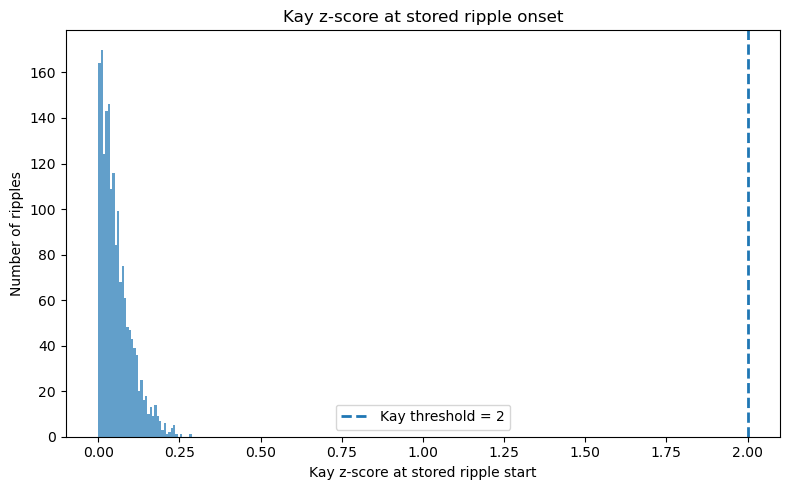

In [13]:
plt.figure(figsize=(8, 5))

plt.hist(
    kay_threshold_check["kay_z_at_start"],
    bins=40,
    alpha=0.7
)

plt.axvline(
    2,
    linestyle="--",
    linewidth=2,
    label="Kay threshold = 2"
)

plt.xlabel("Kay z-score at stored ripple start")
plt.ylabel("Number of ripples")
plt.title("Kay z-score at stored ripple onset")
plt.legend()
plt.tight_layout()
plt.show()

In [14]:
event = offline_s5.iloc[0]

z_event = kay_z.loc[
    (kay_z.index >= event["start_time"]) &
    (kay_z.index <= event["end_time"]),
    "kay_z"
]

if not (z_event > KAY_Z_THRESHOLD).any():
    print('First offline ripple has no sampled Kay z above threshold; skipping example.')
    first_crossing_time = np.nan
    first_crossing_z = np.nan
else:
    first_crossing_time = z_event.index[z_event > KAY_Z_THRESHOLD][0]
    first_crossing_z = z_event.loc[first_crossing_time]

print("Stored start:", event["start_time"])
print("Kay z at stored start:", z_event.iloc[0])

print("First z > 2:", first_crossing_time)
print("Kay z at first crossing:", first_crossing_z)

print(
    "Latency from stored start (ms):",
    (first_crossing_time - event["start_time"]) * 1000
)

Stored start: 1785620828.813188
Kay z at stored start: 0.004509637024556745
First z > 2: 1785620828.8291883
Kay z at first crossing: 2.0806545926146938
Latency from stored start (ms): 16.00027084350586


In [15]:
tp_fn_rows = []

for idx, row in offline_s5.iterrows():

    # Kay event
    kay_start = row["start_time"]
    kay_end = row["end_time"]

    # Kay trace during this event
    z_event = kay_z.loc[
        (kay_z.index >= kay_start) &
        (kay_z.index <= kay_end),
        "kay_z"
    ]

    above = z_event > 2

    if not above.any():
        continue

    # First Kay threshold crossing
    kay_cross_time = z_event.index[above][0]
    kay_cross_z = z_event.loc[kay_cross_time]

    # Find nearest online H5 sample to the Kay crossing
    all_h5_times = online_overlap["timestamp"].to_numpy()
    insertion = np.searchsorted(all_h5_times, kay_cross_time)
    candidate_indices = [max(0, insertion-1), min(len(all_h5_times)-1, insertion)]
    online_idx = min(candidate_indices, key=lambda k: abs(all_h5_times[k] - kay_cross_time))

    online_time = online_overlap.iloc[online_idx]["timestamp"]
    online_z = online_overlap.iloc[online_idx]["z"]

    tp_fn_rows.append({
        "offline_id": idx,
        "kay_start": kay_start,
        "kay_end": kay_end,
        "kay_cross_time": kay_cross_time,
        "kay_cross_z": kay_cross_z,

        "online_time": online_time,
        "online_z_102": online_z,
        "online_margin_102": online_z - 1.5,
    })

kay_cross_comparison = pd.DataFrame(tp_fn_rows)

In [16]:
# Canonical laser-first-pulse labels from Setup 4 (not H5 detection onsets).
print(offline_event_table['event_type'].value_counts())
print('More than one laser train starts in offline ripple:',
      (offline_event_table['n_laser_onsets'] > 1).sum())
print('FN with H5 detection onset (possible lockout/trigger gating):',
      ((offline_event_table['event_type'] == 'FN') &
       offline_event_table['has_h5_detection']).sum())

event_type
FN    1066
TP     671
Name: count, dtype: int64
More than one laser train starts in offline ripple: 11
FN with H5 detection onset (possible lockout/trigger gating): 150


In [17]:
kay_cross_comparison = kay_cross_comparison.merge(
    offline_event_table[["event_type"]],
    left_on="offline_id",
    right_index=True,
    how="left",
    validate="many_to_one"
)

print(kay_cross_comparison["event_type"].value_counts(dropna=False))

event_type
FN    1066
TP     671
Name: count, dtype: int64


In [18]:
kay_cross_comparison[
    kay_cross_comparison["event_type"].isin(["TP", "FN"])
].groupby("event_type")[
    ["kay_cross_z", "online_z_102", "online_margin_102"]
].agg(["count", "mean", "median", "std"])

kay_cross_z                               online_z_102            \
                 count      mean    median       std        count      mean   
event_type                                                                    
FN                1066  2.111923  2.088177  0.095458         1066 -0.119857   
TP                 671  2.107837  2.085909  0.088787          671 -0.040387   

                               online_margin_102                                
              median       std             count      mean    median       std  
event_type                                                                      
FN         -0.210540  0.671336              1066 -1.619857 -1.710540  0.671336  
TP         -0.196924  0.797062               671 -1.540387 -1.696924  0.797062

In [19]:
delays_ms = np.arange(0, 61, 10)

online_times = online_overlap["timestamp"].to_numpy()
online_z = online_overlap["z"].to_numpy()

rows = []

for _, row in kay_cross_comparison.iterrows():

    kay_time = row["kay_cross_time"]

    result = {
        "offline_id": row["offline_id"],
        "event_type": row["event_type"],
    }

    for delay_ms in delays_ms:

        target_time = kay_time + delay_ms / 1000.0

        idx = np.abs(online_times - target_time).argmin()

        z_value = online_z[idx]

        result[f"online_z_{delay_ms}ms"] = z_value
        result[f"online_margin_{delay_ms}ms"] = z_value - 1.5

    rows.append(result)

delay_df = pd.DataFrame(rows)

In [20]:
for delay_ms in delays_ms:

    col = f"online_z_{delay_ms}ms"

    tp = delay_df[delay_df["event_type"] == "TP"]
    fn = delay_df[delay_df["event_type"] == "FN"]

    print(f"\nDelay = {delay_ms} ms")

    print(
        "TP above 1.5:",
        100 * (tp[col] > 1.5).mean(),
        "%"
    )

    print(
        "FN above 1.5:",
        100 * (fn[col] > 1.5).mean(),
        "%"
    )


Delay = 0 ms
TP above 1.5: 4.918032786885246 %
FN above 1.5: 2.25140712945591 %

Delay = 10 ms
TP above 1.5: 11.624441132637854 %
FN above 1.5: 4.127579737335835 %

Delay = 20 ms
TP above 1.5: 21.758569299552907 %
FN above 1.5: 6.285178236397748 %

Delay = 30 ms
TP above 1.5: 15.648286140089418 %
FN above 1.5: 4.784240150093809 %

Delay = 40 ms
TP above 1.5: 9.836065573770492 %
FN above 1.5: 3.564727954971857 %

Delay = 50 ms
TP above 1.5: 8.345752608047691 %
FN above 1.5: 3.0018761726078798 %

Delay = 60 ms
TP above 1.5: 7.451564828614009 %
FN above 1.5: 2.4390243902439024 %


In [21]:
for delay_ms in delays_ms:

    col = f"online_z_{delay_ms}ms"

    tp_median = delay_df.loc[
        delay_df["event_type"] == "TP",
        col
    ].median()

    fn_median = delay_df.loc[
        delay_df["event_type"] == "FN",
        col
    ].median()

    print(
        f"{delay_ms:>2} ms: "
        f"TP median z = {tp_median:.3f}, "
        f"FN median z = {fn_median:.3f}"
    )

 0 ms: TP median z = -0.197, FN median z = -0.211
10 ms: TP median z = 0.256, FN median z = -0.101
20 ms: TP median z = 0.403, FN median z = 0.056
30 ms: TP median z = 0.252, FN median z = -0.051
40 ms: TP median z = 0.079, FN median z = -0.155
50 ms: TP median z = 0.025, FN median z = -0.172
60 ms: TP median z = -0.009, FN median z = -0.233


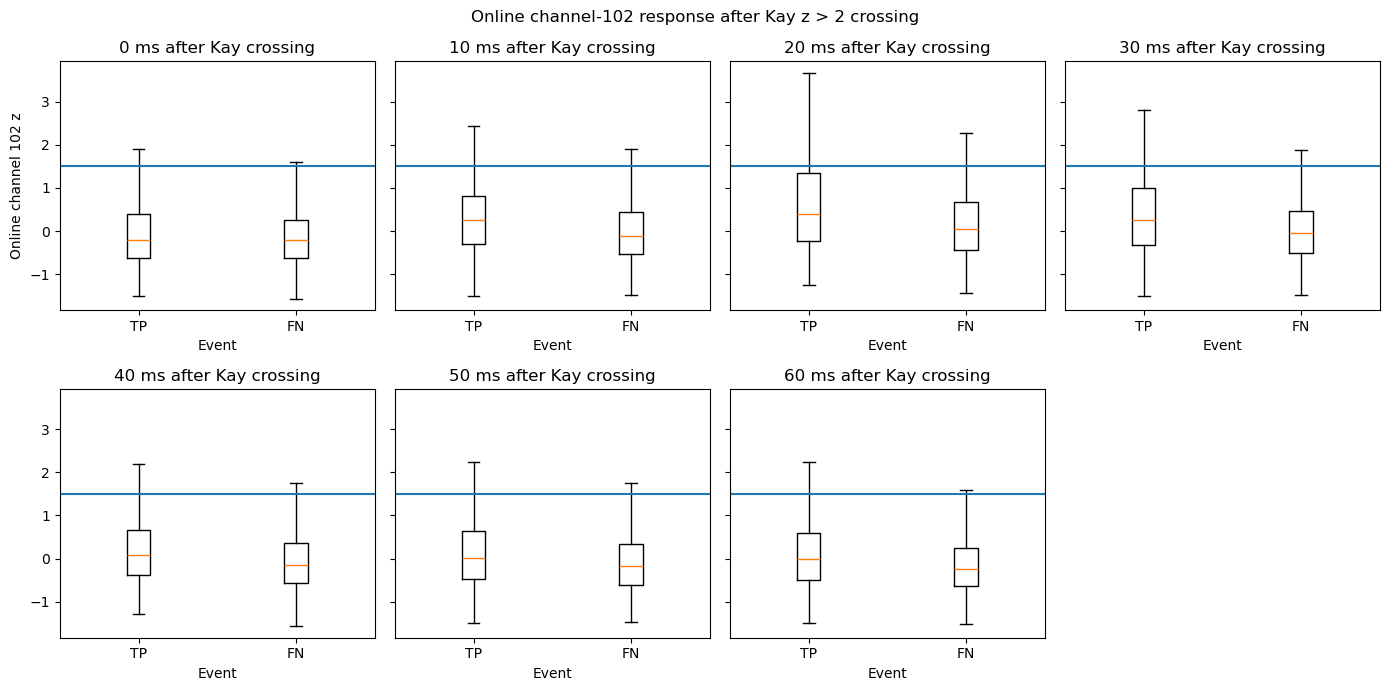

In [22]:
import matplotlib.pyplot as plt

delays_ms = [0, 10, 20, 30, 40, 50, 60]

fig, axes = plt.subplots(
    2, 4,
    figsize=(14, 7),
    sharey=True
)

axes = axes.flatten()

for ax, delay_ms in zip(axes, delays_ms):

    col = f"online_z_{delay_ms}ms"

    tp = delay_df[
        delay_df["event_type"] == "TP"
    ][col].dropna()

    fn = delay_df[
        delay_df["event_type"] == "FN"
    ][col].dropna()

    ax.boxplot(
        [tp, fn],
        labels=["TP", "FN"],
        showfliers=False
    )

    ax.axhline(
        1.5,
        linestyle="-",
        linewidth=1.5
    )

    ax.set_title(f"{delay_ms} ms after Kay crossing")
    ax.set_xlabel("Event")

axes[0].set_ylabel("Online channel 102 z")

# Hide the unused 8th panel
axes[-1].axis("off")

fig.suptitle(
    "Online channel-102 response after Kay z > 2 crossing"
)

plt.tight_layout()
plt.show()

In [23]:
delay_df = delay_df.merge(
    kay_cross_comparison[
        ["offline_id", "kay_cross_z"]
    ],
    on="offline_id",
    how="left"
)

print(delay_df.columns)

Index(['offline_id', 'event_type', 'online_z_0ms', 'online_margin_0ms',
       'online_z_10ms', 'online_margin_10ms', 'online_z_20ms',
       'online_margin_20ms', 'online_z_30ms', 'online_margin_30ms',
       'online_z_40ms', 'online_margin_40ms', 'online_z_50ms',
       'online_margin_50ms', 'online_z_60ms', 'online_margin_60ms',
       'kay_cross_z'],
      dtype='object')


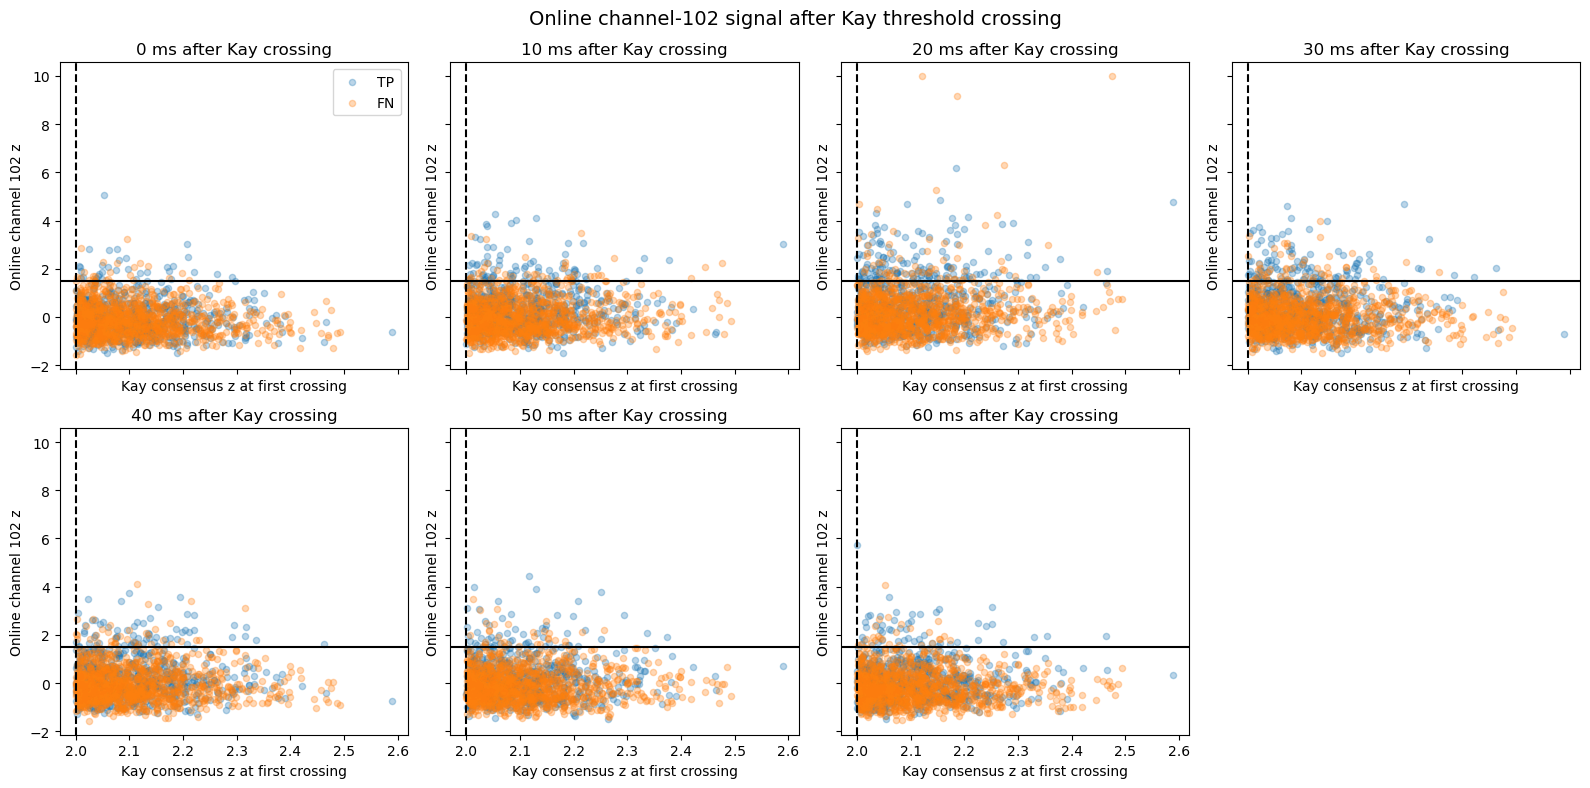

In [24]:
import matplotlib.pyplot as plt
import numpy as np

delays_ms = np.arange(0, 61, 10)

fig, axes = plt.subplots(
    2, 4,
    figsize=(16, 8),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

for ax, delay_ms in zip(axes, delays_ms):

    col = f"online_z_{delay_ms}ms"

    tp = delay_df["event_type"] == "TP"
    fn = delay_df["event_type"] == "FN"

    ax.scatter(
        delay_df.loc[tp, "kay_cross_z"],
        delay_df.loc[tp, col],
        alpha=0.30,
        s=20,
        label="TP"
    )

    ax.scatter(
        delay_df.loc[fn, "kay_cross_z"],
        delay_df.loc[fn, col],
        alpha=0.30,
        s=20,
        label="FN"
    )

    # Kay threshold
    ax.axvline(
        2,
        color="black",
        linestyle="--",
        linewidth=1.5
    )

    # FSGui threshold
    ax.axhline(
        1.5,
        color="black",
        linestyle="-",
        linewidth=1.5
    )

    ax.set_title(f"{delay_ms} ms after Kay crossing")
    ax.set_xlabel("Kay consensus z at first crossing")
    ax.set_ylabel("Online channel 102 z")

# Remove unused 8th panel
axes[-1].axis("off")

# One legend
axes[0].legend()

fig.suptitle(
    "Online channel-102 signal after Kay threshold crossing",
    fontsize=14
)

plt.tight_layout()
plt.show()

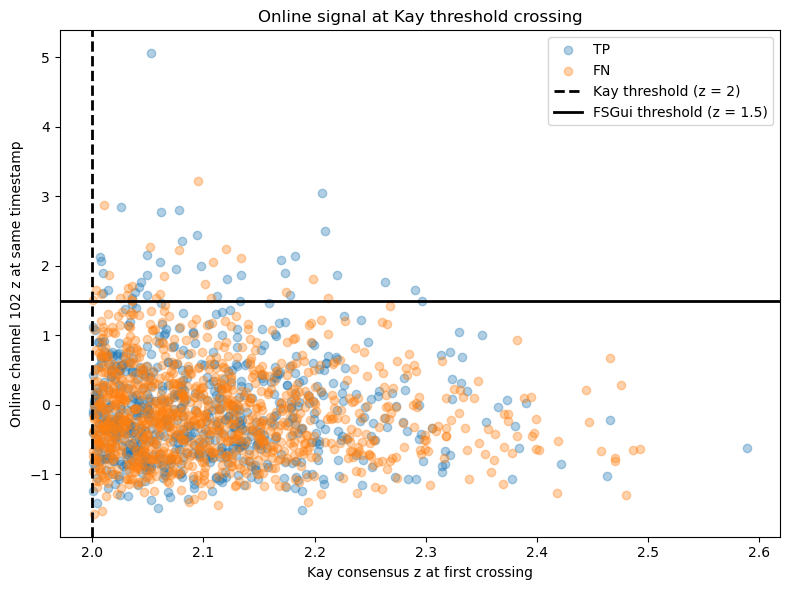

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

tp = kay_cross_comparison["event_type"] == "TP"
fn = kay_cross_comparison["event_type"] == "FN"

plt.scatter(
    kay_cross_comparison.loc[tp, "kay_cross_z"],
    kay_cross_comparison.loc[tp, "online_z_102"],
    alpha=0.35,
    label="TP"
)

plt.scatter(
    kay_cross_comparison.loc[fn, "kay_cross_z"],
    kay_cross_comparison.loc[fn, "online_z_102"],
    alpha=0.35,
    label="FN"
)

plt.axvline(
    2,
    color="black",
    linestyle="--",
    linewidth=2,
    label="Kay threshold (z = 2)"
)

plt.axhline(
    1.5,
    color="black",
    linestyle="-",
    linewidth=2,
    label="FSGui threshold (z = 1.5)"
)
plt.xlabel("Kay consensus z at first crossing")
plt.ylabel("Online channel 102 z at same timestamp")
plt.title("Online signal at Kay threshold crossing")
plt.legend()
plt.tight_layout()
plt.show()

**Interpret only after rerunning with laser-first-pulse TP/FN labels.** The earlier claim about peak TP/FN separation at 20 ms was based on the previous H5-onset classification and is not carried forward.

In [26]:
windows_ms = np.arange(10, 101, 10)

online_times = online_overlap["timestamp"].to_numpy()
online_z = online_overlap["z"].to_numpy()

rows = []

for _, row in kay_cross_comparison.iterrows():

    kay_time = row["kay_cross_time"]

    result = {
        "offline_id": row["offline_id"],
        "event_type": row["event_type"],
        "kay_cross_time": kay_time,
    }

    for window_ms in windows_ms:

        window_end = kay_time + window_ms / 1000.0

        mask = (
            (online_times >= kay_time) &
            (online_times <= window_end)
        )

        z_window = online_z[mask]

        if len(z_window) == 0:
            result[f"online_peak_{window_ms}ms"] = np.nan
            result[f"online_median_{window_ms}ms"] = np.nan
            result[f"online_fraction_gt_1p5_{window_ms}ms"] = np.nan
            result[f"online_any_gt_1p5_{window_ms}ms"] = False
            result[f"online_first_gt_1p5_{window_ms}ms"] = np.nan

        else:
            above = z_window > 1.5

            result[f"online_peak_{window_ms}ms"] = z_window.max()
            result[f"online_median_{window_ms}ms"] = np.median(z_window)
            result[f"online_fraction_gt_1p5_{window_ms}ms"] = above.mean()
            result[f"online_any_gt_1p5_{window_ms}ms"] = above.any()

            if above.any():
                crossing_idx = np.where(mask)[0][np.where(above)[0][0]]
                result[f"online_first_gt_1p5_{window_ms}ms"] = (
                    online_times[crossing_idx] - kay_time
                ) * 1000
            else:
                result[f"online_first_gt_1p5_{window_ms}ms"] = np.nan

    rows.append(result)

cumulative_df = pd.DataFrame(rows)

In [27]:
for window_ms in windows_ms:

    col = f"online_any_gt_1p5_{window_ms}ms"

    tp = cumulative_df[
        cumulative_df["event_type"] == "TP"
    ]

    fn = cumulative_df[
        cumulative_df["event_type"] == "FN"
    ]

    print(f"\nWindow = 0-{window_ms} ms")

    print(
        "TP with online z > 1.5:",
        100 * tp[col].mean(),
        "%"
    )

    print(
        "FN with online z > 1.5:",
        100 * fn[col].mean(),
        "%"
    )


Window = 0-10 ms
TP with online z > 1.5: 15.946348733233979 %
FN with online z > 1.5: 6.848030018761726 %

Window = 0-20 ms
TP with online z > 1.5: 34.277198211624444 %
FN with online z > 1.5: 14.352720450281426 %

Window = 0-30 ms
TP with online z > 1.5: 46.944858420268254 %
FN with online z > 1.5: 19.136960600375236 %

Window = 0-40 ms
TP with online z > 1.5: 55.73770491803278 %
FN with online z > 1.5: 23.076923076923077 %

Window = 0-50 ms
TP with online z > 1.5: 60.65573770491803 %
FN with online z > 1.5: 25.515947467166978 %

Window = 0-60 ms
TP with online z > 1.5: 65.27570789865872 %
FN with online z > 1.5: 28.23639774859287 %

Window = 0-70 ms
TP with online z > 1.5: 70.6408345752608 %
FN with online z > 1.5: 30.393996247654787 %

Window = 0-80 ms
TP with online z > 1.5: 73.6214605067064 %
FN with online z > 1.5: 31.894934333958723 %

Window = 0-90 ms
TP with online z > 1.5: 76.45305514157972 %
FN with online z > 1.5: 33.67729831144465 %

Window = 0-100 ms
TP with online z > 1

In [28]:
for window_ms in windows_ms:

    col = f"online_peak_{window_ms}ms"

    tp_median = cumulative_df.loc[
        cumulative_df["event_type"] == "TP",
        col
    ].median()

    fn_median = cumulative_df.loc[
        cumulative_df["event_type"] == "FN",
        col
    ].median()

    print(
        f"{window_ms:2d} ms: "
        f"TP median peak = {tp_median:.3f}, "
        f"FN median peak = {fn_median:.3f}"
    )

10 ms: TP median peak = 0.495, FN median peak = 0.255
20 ms: TP median peak = 1.055, FN median peak = 0.633
30 ms: TP median peak = 1.371, FN median peak = 0.842
40 ms: TP median peak = 1.629, FN median peak = 0.976
50 ms: TP median peak = 1.712, FN median peak = 1.061
60 ms: TP median peak = 1.811, FN median peak = 1.112
70 ms: TP median peak = 1.918, FN median peak = 1.161
80 ms: TP median peak = 1.987, FN median peak = 1.209
90 ms: TP median peak = 2.013, FN median peak = 1.238
100 ms: TP median peak = 2.062, FN median peak = 1.280


In [29]:
for window_ms in windows_ms:

    col = f"online_first_gt_1p5_{window_ms}ms"

    tp = cumulative_df[
        cumulative_df["event_type"] == "TP"
    ][col]

    print(
        f"{window_ms:2d} ms: "
        f"TP events crossing online threshold = "
        f"{tp.notna().mean() * 100:.1f}%"
    )

10 ms: TP events crossing online threshold = 15.9%
20 ms: TP events crossing online threshold = 34.3%
30 ms: TP events crossing online threshold = 46.9%
40 ms: TP events crossing online threshold = 55.7%
50 ms: TP events crossing online threshold = 60.7%
60 ms: TP events crossing online threshold = 65.3%
70 ms: TP events crossing online threshold = 70.6%
80 ms: TP events crossing online threshold = 73.6%
90 ms: TP events crossing online threshold = 76.5%
100 ms: TP events crossing online threshold = 78.8%


In [30]:
window_ms = 100

rows = []

online_times = online_overlap["timestamp"].to_numpy()
online_z = online_overlap["z"].to_numpy()

for _, row in kay_cross_comparison.iterrows():

    kay_time = row["kay_cross_time"]
    window_end = kay_time + window_ms / 1000.0

    mask = (
        (online_times >= kay_time) &
        (online_times <= window_end)
    )

    z_window = online_z[mask]

    if len(z_window) == 0:
        continue

    max_z = z_window.max()
    median_z = np.median(z_window)

    rows.append({
        "offline_id": row["offline_id"],
        "event_type": row["event_type"],
        "online_max_z_100ms": max_z,
        "online_max_margin_100ms": max_z - 1.5,
        "online_median_z_100ms": median_z,
        "online_fraction_gt_1p5_100ms":
            (z_window > 1.5).mean(),
    })

tp_fn_100ms = pd.DataFrame(rows)

In [31]:
tp_fn_100ms.groupby("event_type")[
    [
        "online_max_z_100ms",
        "online_max_margin_100ms",
        "online_median_z_100ms",
        "online_fraction_gt_1p5_100ms",
    ]
].agg(["count", "mean", "median", "std"])

online_max_z_100ms                                \
                        count      mean    median       std   
event_type                                                    
FN                       1066  1.415543  1.280160  0.878932   
TP                        671  2.216186  2.061755  0.989820   

           online_max_margin_100ms                                \
                             count      mean    median       std   
event_type                                                         
FN                            1066 -0.084457 -0.219840  0.878932   
TP                             671  0.716186  0.561755  0.989820   

           online_median_z_100ms                                \
                           count      mean    median       std   
event_type                                                       
FN                          1066 -0.141091 -0.161514  0.294791   
TP                           671  0.068793  0.056922  0.333148   

           online_fraction_gt_1p5_100ms                                
                                  count      mean    median       std  
event_type                                                             
FN                                 1066  0.031784  0.000000  0.059409  
TP                                  671  0.098849  0.086667  0.088850

In [32]:
for delay_ms in delays_ms:

    col = f"online_z_{delay_ms}ms"

    tp_median = delay_df.loc[
        delay_df["event_type"] == "TP",
        col
    ].median()

    fn_median = delay_df.loc[
        delay_df["event_type"] == "FN",
        col
    ].median()

    print(
        f"{delay_ms:>2} ms: "
        f"TP median z = {tp_median:.3f}, "
        f"FN median z = {fn_median:.3f}"
    )

 0 ms: TP median z = -0.197, FN median z = -0.211
10 ms: TP median z = 0.256, FN median z = -0.101
20 ms: TP median z = 0.403, FN median z = 0.056
30 ms: TP median z = 0.252, FN median z = -0.051
40 ms: TP median z = 0.079, FN median z = -0.155
50 ms: TP median z = 0.025, FN median z = -0.172
60 ms: TP median z = -0.009, FN median z = -0.233


## 60ms

In [33]:
window_ms = 60

rows = []

online_times = online_overlap["timestamp"].to_numpy()
online_z = online_overlap["z"].to_numpy()

for _, row in kay_cross_comparison.iterrows():

    kay_time = row["kay_cross_time"]
    window_end = kay_time + window_ms / 1000.0

    mask = (
        (online_times >= kay_time) &
        (online_times <= window_end)
    )

    z_window = online_z[mask]

    if len(z_window) == 0:
        continue

    max_z = z_window.max()
    median_z = np.median(z_window)

    rows.append({
        "offline_id": row["offline_id"],
        "event_type": row["event_type"],
        "online_max_z_60ms": max_z,
        "online_max_margin_60ms": max_z - 1.5,
        "online_median_z_60ms": median_z,
        "online_fraction_gt_1p5_60ms":
            (z_window > 1.5).mean(),
    })

tp_fn_60ms = pd.DataFrame(rows)

In [34]:
tp_fn_60ms.groupby("event_type")[
    [
        "online_max_z_60ms",
        "online_max_margin_60ms",
        "online_median_z_60ms",
        "online_fraction_gt_1p5_60ms",
    ]
].agg(["count", "mean", "median", "std"])

online_max_z_60ms                                \
                       count      mean    median       std   
event_type                                                   
FN                      1066  1.245833  1.112392  0.917366   
TP                       671  1.958335  1.810532  1.035812   

           online_max_margin_60ms                                \
                            count      mean    median       std   
event_type                                                        
FN                           1066 -0.254167 -0.387608  0.917366   
TP                            671  0.458335  0.310532  1.035812   

           online_median_z_60ms                                \
                          count      mean    median       std   
event_type                                                      
FN                         1066 -0.067880 -0.110370  0.385406   
TP                          671  0.192032  0.147039  0.462010   

           online_fraction_gt_1p5_60ms                                
                                 count      mean    median       std  
event_type                                                            
FN                                1066  0.039450  0.000000  0.083448  
TP                                 671  0.119527  0.089888  0.129873

In [35]:
windows_ms = [10, 15, 20, 30, 40, 50, 60]

online_times = online_overlap["timestamp"].to_numpy()
online_z = online_overlap["z"].to_numpy()

rows = []

for _, row in kay_cross_comparison.iterrows():

    kay_time = row["kay_cross_time"]

    result = {
        "offline_id": row["offline_id"],
        "event_type": row["event_type"],
    }

    for window_ms in windows_ms:

        window_end = kay_time + window_ms / 1000.0

        mask = (
            (online_times >= kay_time) &
            (online_times <= window_end)
        )

        z_window = online_z[mask]

        if len(z_window) == 0:
            result[f"online_max_z_{window_ms}ms"] = np.nan
            result[f"online_max_margin_{window_ms}ms"] = np.nan
            result[f"online_median_z_{window_ms}ms"] = np.nan
            result[f"online_fraction_gt_1p5_{window_ms}ms"] = np.nan
        else:
            max_z = z_window.max()

            result[f"online_max_z_{window_ms}ms"] = max_z
            result[f"online_max_margin_{window_ms}ms"] = max_z - 1.5
            result[f"online_median_z_{window_ms}ms"] = np.median(z_window)
            result[f"online_fraction_gt_1p5_{window_ms}ms"] = (
                z_window > 1.5
            ).mean()

    rows.append(result)

tp_fn_windows = pd.DataFrame(rows)

print(tp_fn_windows.shape)
print(tp_fn_windows.columns.tolist())

(1737, 30)
['offline_id', 'event_type', 'online_max_z_10ms', 'online_max_margin_10ms', 'online_median_z_10ms', 'online_fraction_gt_1p5_10ms', 'online_max_z_15ms', 'online_max_margin_15ms', 'online_median_z_15ms', 'online_fraction_gt_1p5_15ms', 'online_max_z_20ms', 'online_max_margin_20ms', 'online_median_z_20ms', 'online_fraction_gt_1p5_20ms', 'online_max_z_30ms', 'online_max_margin_30ms', 'online_median_z_30ms', 'online_fraction_gt_1p5_30ms', 'online_max_z_40ms', 'online_max_margin_40ms', 'online_median_z_40ms', 'online_fraction_gt_1p5_40ms', 'online_max_z_50ms', 'online_max_margin_50ms', 'online_median_z_50ms', 'online_fraction_gt_1p5_50ms', 'online_max_z_60ms', 'online_max_margin_60ms', 'online_median_z_60ms', 'online_fraction_gt_1p5_60ms']


In [36]:
# For every Kay crossing, find nearest H5 timestamp
cross_times = kay_cross_comparison["kay_cross_time"].to_numpy()
insertions = np.searchsorted(online_times, cross_times)
right_idx = np.clip(insertions, 0, len(online_times)-1)
left_idx = np.clip(insertions-1, 0, len(online_times)-1)
nearest_idx = np.where(np.abs(online_times[left_idx]-cross_times) <= np.abs(online_times[right_idx]-cross_times), left_idx, right_idx)

nearest_diffs_ms = (
    online_times[nearest_idx]
    - kay_cross_comparison["kay_cross_time"].to_numpy()
) * 1000

print("Maximum mismatch (ms):", np.max(np.abs(nearest_diffs_ms)))
print("Median mismatch (ms):", np.median(np.abs(nearest_diffs_ms)))
print("95th percentile (ms):", np.percentile(np.abs(nearest_diffs_ms), 95))

Maximum mismatch (ms): 1.3496875762939453
Median mismatch (ms): 0.16641616821289062
95th percentile (ms): 0.32868385314941395


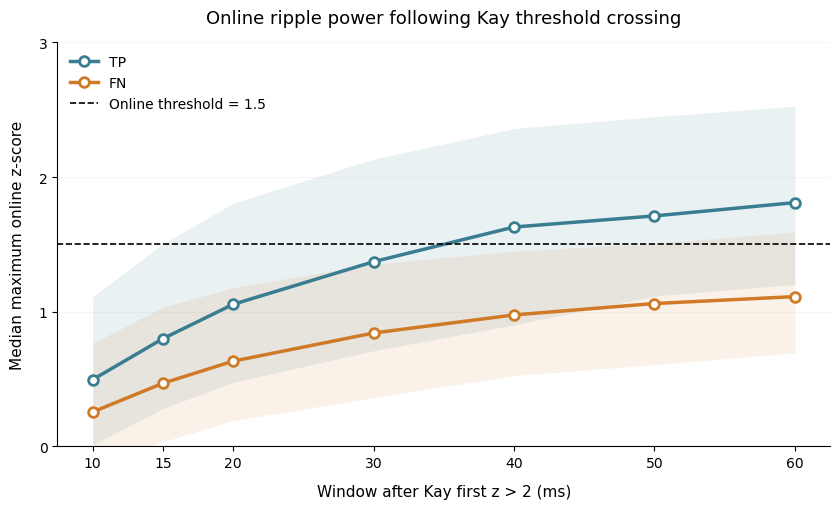

In [67]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. CALCULATE MEDIAN AND IQR
# ============================================================

tp_medians = []
fn_medians = []

tp_q25 = []
tp_q75 = []

fn_q25 = []
fn_q75 = []

for window_ms in windows_ms:

    col = f"online_max_z_{window_ms}ms"

    tp_vals = tp_fn_windows.loc[
        tp_fn_windows["event_type"] == "TP", col
    ].dropna().to_numpy(dtype=float)

    fn_vals = tp_fn_windows.loc[
        tp_fn_windows["event_type"] == "FN", col
    ].dropna().to_numpy(dtype=float)

    tp_medians.append(np.median(tp_vals))
    fn_medians.append(np.median(fn_vals))

    tp_q25.append(np.percentile(tp_vals, 25))
    tp_q75.append(np.percentile(tp_vals, 75))

    fn_q25.append(np.percentile(fn_vals, 25))
    fn_q75.append(np.percentile(fn_vals, 75))

tp_medians = np.asarray(tp_medians)
fn_medians = np.asarray(fn_medians)

tp_q25 = np.asarray(tp_q25)
tp_q75 = np.asarray(tp_q75)

fn_q25 = np.asarray(fn_q25)
fn_q75 = np.asarray(fn_q75)

# ============================================================
# 2. PLOT SETTINGS
# ============================================================

tp_color = "#3A7D91"
fn_color = "#D07A28"

fig, ax = plt.subplots(figsize=(8.5, 5.2))

# ============================================================
# 3. IQR SHADING
# ============================================================

ax.fill_between(
    windows_ms,
    tp_q25,
    tp_q75,
    color=tp_color,
    alpha=0.10,
    linewidth=0
)

ax.fill_between(
    windows_ms,
    fn_q25,
    fn_q75,
    color=fn_color,
    alpha=0.10,
    linewidth=0
)

# ============================================================
# 4. MEDIAN LINES
# ============================================================

ax.plot(
    windows_ms,
    tp_medians,
    color=tp_color,
    linewidth=2.5,
    marker="o",
    markersize=7,
    markerfacecolor="white",
    markeredgecolor=tp_color,
    markeredgewidth=2,
    label="TP"
)

ax.plot(
    windows_ms,
    fn_medians,
    color=fn_color,
    linewidth=2.5,
    marker="o",
    markersize=7,
    markerfacecolor="white",
    markeredgecolor=fn_color,
    markeredgewidth=2,
    label="FN"
)

# ============================================================
# 5. ONLINE THRESHOLD
# ============================================================

ax.axhline(
    1.5,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Online threshold = 1.5"
)

# ============================================================
# 6. AXES AND LABELS
# ============================================================

ax.set_xlabel(
    "Window after Kay first z > 2 (ms)",
    fontsize=11,
    labelpad=10
)

ax.set_ylabel(
    "Median maximum online z-score",
    fontsize=11,
    labelpad=10
)

ax.set_title(
    "Online ripple power following Kay threshold crossing",
    fontsize=13,
    pad=14
)

ax.set_xticks(windows_ms)

# Preserve the full IQR range
ymax = max(
    np.nanmax(tp_q75),
    np.nanmax(fn_q75),
    1.5
)

upper_limit = np.ceil((ymax + 0.15) / 1.0) * 1.0

ax.set_ylim(0, upper_limit)

# Y-axis tick increments of 1.0
ax.set_yticks(
    np.arange(0, upper_limit + 0.1, 1.0)
)

# ============================================================
# 7. STYLING
# ============================================================

ax.grid(
    axis="y",
    alpha=0.12,
    linewidth=0.8
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(
    axis="both",
    labelsize=10
)

ax.legend(
    frameon=False,
    loc="upper left",
    fontsize=10
)

plt.tight_layout()
plt.show()


In [38]:
# ------------------------------------------------------------
# Kay crossing analysis — new variable names
# ------------------------------------------------------------

kay_cross_analysis = tp_fn_60ms[
    tp_fn_60ms["event_type"].isin(["TP", "FN"])
].copy()

# Add Kay z at first threshold crossing
kay_cross_analysis = kay_cross_analysis.merge(
    kay_cross_comparison[
        ["offline_id", "kay_cross_z"]
    ],
    on="offline_id",
    how="left"
)

# ------------------------------------------------------------
# Kay crossing-z bins
# ------------------------------------------------------------

cross_bins = [
    2.0, 2.5, 3.0, 3.5, 4.0, 4.5, np.inf
]

cross_labels = [
    "2.0-2.5",
    "2.5-3.0",
    "3.0-3.5",
    "3.5-4.0",
    "4.0-4.5",
    "4.5+"
]

kay_cross_analysis["crossing_z_bin"] = pd.cut(
    kay_cross_analysis["kay_cross_z"],
    bins=cross_bins,
    labels=cross_labels,
    right=False
)

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

kay_cross_summary = (
    kay_cross_analysis
    .groupby("crossing_z_bin", observed=False)
    .agg(
        total_events=("offline_id", "count"),

        TP=("event_type", lambda x: (x == "TP").sum()),
        FN=("event_type", lambda x: (x == "FN").sum()),

        online_max_z_median=(
            "online_max_z_60ms",
            "median"
        ),

        online_max_z_mean=(
            "online_max_z_60ms",
            "mean"
        ),

        online_max_z_std=(
            "online_max_z_60ms",
            "std"
        )
    )
)

kay_cross_summary["TP_percent"] = (
    kay_cross_summary["TP"]
    / kay_cross_summary["total_events"]
    * 100
)

kay_cross_summary["FN_percent"] = (
    kay_cross_summary["FN"]
    / kay_cross_summary["total_events"]
    * 100
)

kay_cross_summary

,total_events,TP,FN,online_max_z_median,online_max_z_mean,online_max_z_std,TP_percent,FN_percent
crossing_z_bin,,,,,,,,
2.0-2.5,1736,670,1066,1.334171,1.518140,1.018065,38.59447,61.40553
2.5-3.0,1,1,0,6.609714,6.609714,NaN,100.00000,0.00000
3.0-3.5,0,0,0,NaN,NaN,NaN,NaN,NaN
3.5-4.0,0,0,0,NaN,NaN,NaN,NaN,NaN
4.0-4.5,0,0,0,NaN,NaN,NaN,NaN,NaN
4.5+,0,0,0,NaN,NaN,NaN,NaN,NaN


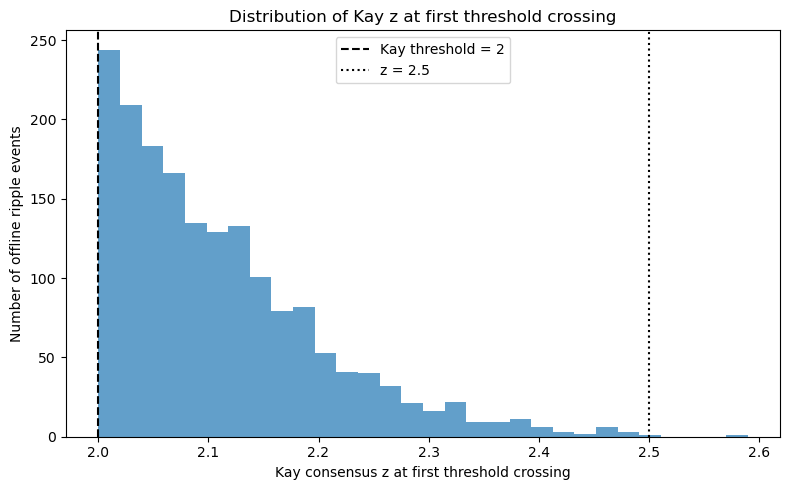

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    kay_cross_analysis["kay_cross_z"],
    bins=30,
    alpha=0.7
)

plt.axvline(
    2.0,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Kay threshold = 2"
)

plt.axvline(
    2.5,
    color="black",
    linestyle=":",
    linewidth=1.5,
    label="z = 2.5"
)

plt.xlabel("Kay consensus z at first threshold crossing")
plt.ylabel("Number of offline ripple events")
plt.title("Distribution of Kay z at first threshold crossing")
plt.legend()

plt.tight_layout()
plt.show()

In [40]:
# ============================================================
# Kay strength analysis — NEW variables only
# ============================================================

kay_strength_analysis = tp_fn_60ms[
    tp_fn_60ms["event_type"].isin(["TP", "FN"])
].copy()

# Add Kay max z-score
kay_strength_analysis = kay_strength_analysis.merge(
    offline_s5[["max_zscore"]].rename_axis("offline_id").reset_index(),
    on="offline_id",
    how="left"
)

# ------------------------------------------------------------
# Kay strength bins
# ------------------------------------------------------------

strength_bins = [2, 3, 4, 5, 6, np.inf]

strength_labels = [
    "2–3",
    "3–4",
    "4–5",
    "5–6",
    "6+"
]

kay_strength_analysis["kay_strength_bin"] = pd.cut(
    kay_strength_analysis["max_zscore"],
    bins=strength_bins,
    labels=strength_labels,
    right=False
)

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

kay_strength_summary_v2 = (
    kay_strength_analysis
    .groupby("kay_strength_bin", observed=False)
    .agg(
        total_events=("offline_id", "count"),

        TP=("event_type", lambda x: (x == "TP").sum()),
        FN=("event_type", lambda x: (x == "FN").sum()),

        online_max_z_median=(
            "online_max_z_60ms",
            "median"
        ),

        online_max_z_mean=(
            "online_max_z_60ms",
            "mean"
        )
    )
)

kay_strength_summary_v2["TP_percent"] = (
    kay_strength_summary_v2["TP"]
    / kay_strength_summary_v2["total_events"]
    * 100
)

kay_strength_summary_v2["FN_percent"] = (
    kay_strength_summary_v2["FN"]
    / kay_strength_summary_v2["total_events"]
    * 100
)

kay_strength_summary_v2

,total_events,TP,FN,online_max_z_median,online_max_z_mean,TP_percent,FN_percent
kay_strength_bin,,,,,,,
2–3,197,48,149,1.273163,1.387954,24.365482,75.634518
3–4,542,150,392,1.211715,1.352857,27.675277,72.324723
4–5,500,185,315,1.265456,1.450631,37.000000,63.000000
5–6,320,167,153,1.457064,1.685476,52.187500,47.812500
6+,178,121,57,1.791082,2.082905,67.977528,32.022472


The first sampled Kay z above threshold will often be close to the crossing threshold; it should not be confused with ripple strength. Use the event maximum (e.g., `max_zscore`) when testing whether stronger offline ripples are more likely to trigger laser stimulation.

In [41]:
print(
    offline_s5["max_zscore"].describe()
)

count    1737.000000
mean        4.369839
std         1.182223
min         2.252553
25%         3.455084
50%         4.205140
75%         5.122553
max        10.265420
Name: max_zscore, dtype: float64


In [42]:
df = tp_fn_60ms[
    tp_fn_60ms["event_type"].isin(["TP", "FN"])
].copy()

# Add Kay's maximum z for each offline ripple
df = df.merge(
    offline_s5[["max_zscore"]].rename_axis("offline_id").reset_index(),
    on="offline_id",
    how="left"
)

# Kay ripple-strength bins
bins = [2.0, 3.0, 4.0, 5.0, 6.0, np.inf]

labels = [
    "2.0-3.0",
    "3.0-4.0",
    "4.0-5.0",
    "5.0-6.0",
    "6.0+"
]

df["kay_strength_bin"] = pd.cut(
    df["max_zscore"],
    bins=bins,
    labels=labels,
    right=False
)

summary = (
    df.groupby("kay_strength_bin", observed=False)
    .agg(
        total_events=("offline_id", "count"),
        TP=("event_type", lambda x: (x == "TP").sum()),
        FN=("event_type", lambda x: (x == "FN").sum()),
        online_max_z_median=("online_max_z_60ms", "median"),
        online_max_z_mean=("online_max_z_60ms", "mean"),
        online_max_z_std=("online_max_z_60ms", "std")
    )
)

summary["TP_percent"] = (
    summary["TP"] / summary["total_events"] * 100
)

summary["FN_percent"] = (
    summary["FN"] / summary["total_events"] * 100
)

summary

,total_events,TP,FN,online_max_z_median,online_max_z_mean,online_max_z_std,TP_percent,FN_percent
kay_strength_bin,,,,,,,,
2.0-3.0,197,48,149,1.273163,1.387954,0.863949,24.365482,75.634518
3.0-4.0,542,150,392,1.211715,1.352857,0.842191,27.675277,72.324723
4.0-5.0,500,185,315,1.265456,1.450631,0.936372,37.000000,63.000000
5.0-6.0,320,167,153,1.457064,1.685476,1.066980,52.187500,47.812500
6.0+,178,121,57,1.791082,2.082905,1.516971,67.977528,32.022472


Offline side:
For each Kay ripple, take its maximum Kay max_zscore over that entire offline ripple.
Online side:
For that same Kay ripple, we take the maximum online channel-102 z-score during the 60 ms after the Kay first \(z>2\) crossing.
So each Kay ripple gets two numbers:
\[
Z_{\text{Kay,max}} =
\max(\text{Kay consensus z during the stored Kay ripple})
\]
and
\[
Z_{\text{online,max,60ms}} =
\max(\text{online channel-102 z from Kay crossing to +60 ms})
\]
For example:

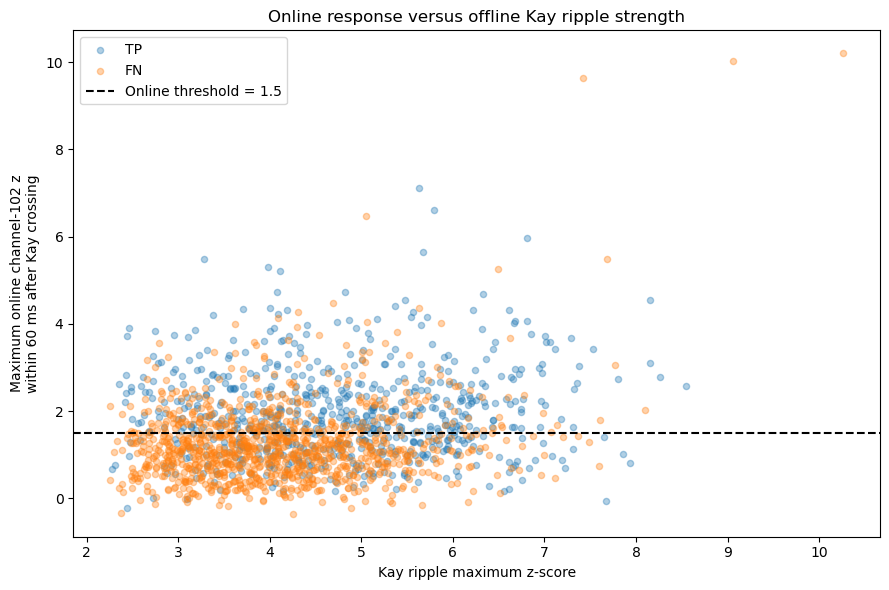

In [43]:
import matplotlib.pyplot as plt

# Use the event-level dataframe we already built
plot_df = df[
    df["event_type"].isin(["TP", "FN"])
].copy()

plt.figure(figsize=(9, 6))

tp = plot_df["event_type"] == "TP"
fn = plot_df["event_type"] == "FN"

plt.scatter(
    plot_df.loc[tp, "max_zscore"],
    plot_df.loc[tp, "online_max_z_60ms"],
    alpha=0.35,
    s=20,
    label="TP"
)

plt.scatter(
    plot_df.loc[fn, "max_zscore"],
    plot_df.loc[fn, "online_max_z_60ms"],
    alpha=0.35,
    s=20,
    label="FN"
)

# Online threshold
plt.axhline(
    1.5,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Online threshold = 1.5"
)

plt.xlabel("Kay ripple maximum z-score")
plt.ylabel("Maximum online channel-102 z\nwithin 60 ms after Kay crossing")
plt.title("Online response versus offline Kay ripple strength")
plt.legend()
plt.tight_layout()
plt.show()

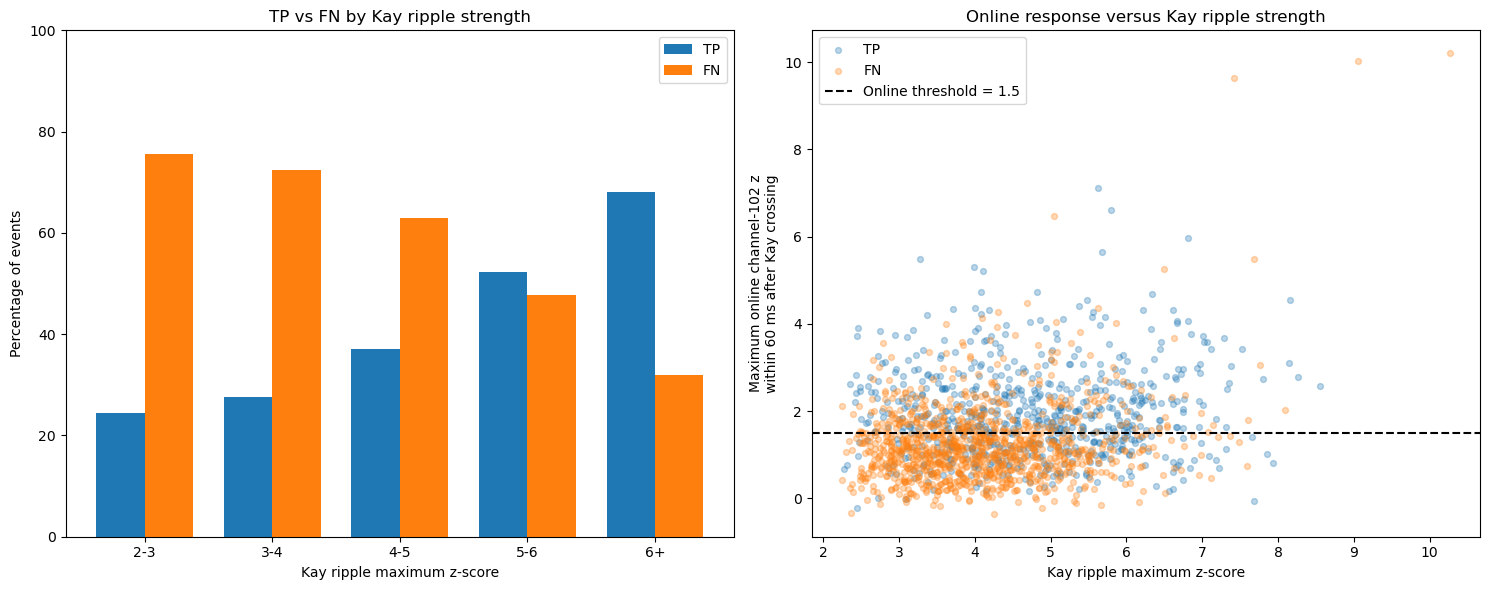

In [44]:
import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# Prepare event-level data
# ------------------------------------------------------------

plot_df = tp_fn_60ms[
    tp_fn_60ms["event_type"].isin(["TP", "FN"])
].copy()

plot_df = plot_df.merge(
    offline_s5[
        ["max_zscore"]
    ].rename_axis("offline_id").reset_index(),
    on="offline_id",
    how="left"
)

# ------------------------------------------------------------
# Kay strength bins for left panel
# ------------------------------------------------------------

bins = [2, 3, 4, 5, 6, np.inf]

labels = [
    "2-3",
    "3-4",
    "4-5",
    "5-6",
    "6+"
]

plot_df["kay_strength_bin"] = pd.cut(
    plot_df["max_zscore"],
    bins=bins,
    labels=labels,
    right=False
)

# Summary for bar chart
bar_summary = (
    plot_df
    .groupby("kay_strength_bin", observed=False)
    .agg(
        total=("offline_id", "count"),
        TP=("event_type", lambda x: (x == "TP").sum()),
        FN=("event_type", lambda x: (x == "FN").sum())
    )
)

bar_summary["TP_percent"] = (
    bar_summary["TP"] /
    bar_summary["total"] * 100
)

bar_summary["FN_percent"] = (
    bar_summary["FN"] /
    bar_summary["total"] * 100
)

# ------------------------------------------------------------
# Figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6)
)

x = np.arange(len(labels))
width = 0.38

# ============================================================
# LEFT: TP / FN BAR CHART
# ============================================================

axes[0].bar(
    x - width / 2,
    bar_summary["TP_percent"],
    width,
    label="TP"
)

axes[0].bar(
    x + width / 2,
    bar_summary["FN_percent"],
    width,
    label="FN"
)

axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)

axes[0].set_xlabel(
    "Kay ripple maximum z-score"
)

axes[0].set_ylabel(
    "Percentage of events"
)

axes[0].set_title(
    "TP vs FN by Kay ripple strength"
)

axes[0].set_ylim(0, 100)

axes[0].legend()

# ============================================================
# RIGHT: INDIVIDUAL EVENT SCATTER
# ============================================================

tp = plot_df["event_type"] == "TP"
fn = plot_df["event_type"] == "FN"

axes[1].scatter(
    plot_df.loc[tp, "max_zscore"],
    plot_df.loc[tp, "online_max_z_60ms"],
    s=18,
    alpha=0.30,
    label="TP"
)

axes[1].scatter(
    plot_df.loc[fn, "max_zscore"],
    plot_df.loc[fn, "online_max_z_60ms"],
    s=18,
    alpha=0.30,
    label="FN"
)

axes[1].axhline(
    1.5,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Online threshold = 1.5"
)

axes[1].set_xlabel(
    "Kay ripple maximum z-score"
)

axes[1].set_ylabel(
    "Maximum online channel-102 z\nwithin 60 ms after Kay crossing"
)

axes[1].set_title(
    "Online response versus Kay ripple strength"
)

axes[1].legend()

plt.tight_layout()
plt.show()

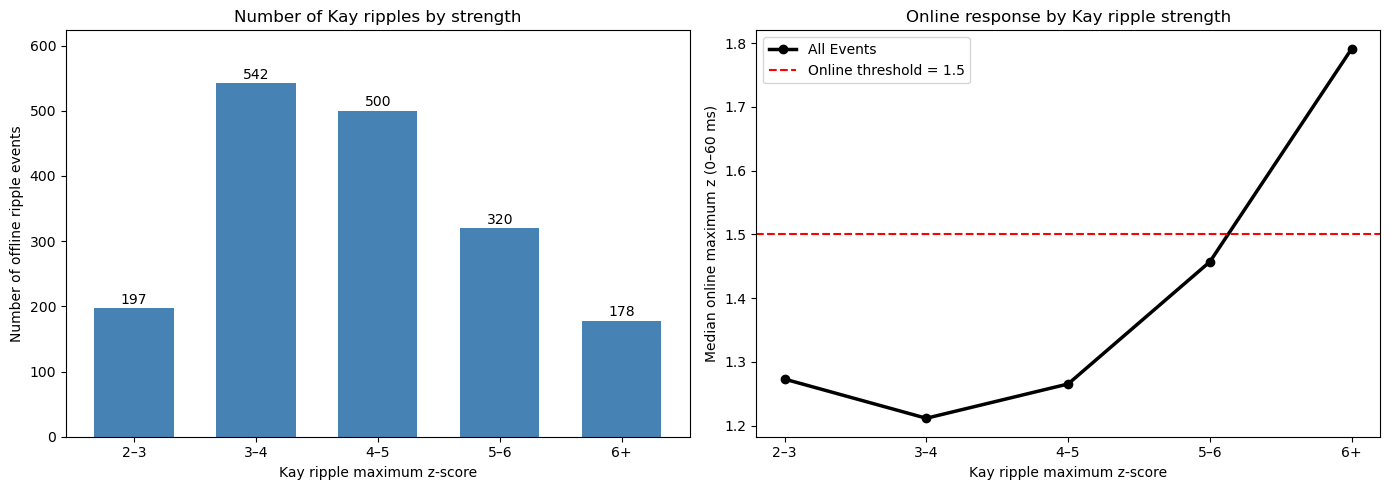

In [45]:
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# Prepare data
# ============================================================

all_events_summary = kay_strength_summary_v2[
    kay_strength_summary_v2["total_events"] > 0
].copy()

all_events_medians = (
    kay_strength_analysis
    .groupby("kay_strength_bin", observed=False)["online_max_z_60ms"]
    .median()
    .reindex(all_events_summary.index)
)

all_events_counts = all_events_summary["total_events"]

all_events_x = np.arange(len(all_events_summary))
all_events_labels = all_events_summary.index.astype(str)

# ============================================================
# Create figure: 2 panels
# ============================================================

all_events_fig, all_events_axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

# ============================================================
# LEFT: Number of offline Kay ripple events
# ============================================================

all_events_bars = all_events_axes[0].bar(
    all_events_x,
    all_events_counts,
    color="steelblue",
    width=0.65
)

all_events_axes[0].set_xticks(all_events_x)
all_events_axes[0].set_xticklabels(all_events_labels)

all_events_axes[0].set_xlabel("Kay ripple maximum z-score")
all_events_axes[0].set_ylabel("Number of offline ripple events")
all_events_axes[0].set_title("Number of Kay ripples by strength")

# Add event counts above bars
for all_events_bar in all_events_bars:
    all_events_height = all_events_bar.get_height()

    all_events_axes[0].text(
        all_events_bar.get_x() + all_events_bar.get_width() / 2,
        all_events_height + 2,
        f"{int(all_events_height)}",
        ha="center",
        va="bottom"
    )

all_events_axes[0].set_ylim(
    0,
    all_events_counts.max() * 1.15
)

# ============================================================
# RIGHT: All Events median online z-score
# ============================================================

all_events_axes[1].plot(
    all_events_x,
    all_events_medians,
    marker="o",
    linewidth=2.5,
    color="black",
    label="All Events"
)

all_events_axes[1].axhline(
    1.5,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="Online threshold = 1.5"
)

all_events_axes[1].set_xticks(all_events_x)
all_events_axes[1].set_xticklabels(all_events_labels)

all_events_axes[1].set_xlabel("Kay ripple maximum z-score")
all_events_axes[1].set_ylabel("Median online maximum z (0–60 ms)")
all_events_axes[1].set_title("Online response by Kay ripple strength")

all_events_axes[1].legend()

plt.tight_layout()
plt.show()

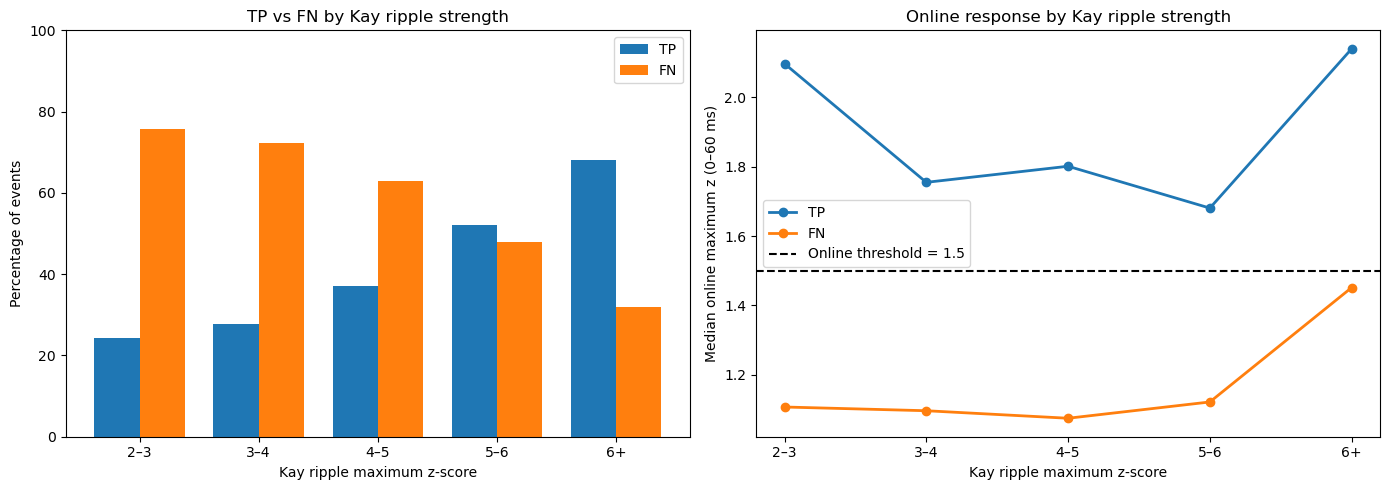

In [46]:
import matplotlib.pyplot as plt
import numpy as np

plot_summary = kay_strength_summary_v2[
    kay_strength_summary_v2["total_events"] > 0
].copy()

x = np.arange(len(plot_summary))
labels = plot_summary.index.astype(str)

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

# ============================================================
# LEFT: TP / FN percentage
# ============================================================

width = 0.38

axes[0].bar(
    x - width / 2,
    plot_summary["TP_percent"],
    width,
    label="TP"
)

axes[0].bar(
    x + width / 2,
    plot_summary["FN_percent"],
    width,
    label="FN"
)

axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)

axes[0].set_xlabel(
    "Kay ripple maximum z-score"
)

axes[0].set_ylabel(
    "Percentage of events"
)

axes[0].set_title(
    "TP vs FN by Kay ripple strength"
)

axes[0].set_ylim(0, 100)
axes[0].legend()


# ============================================================
# RIGHT: ONLINE MAX Z — TP VS FN
# ============================================================
medians_by_type = (
    kay_strength_analysis
    .groupby(
        ["kay_strength_bin", "event_type"],
        observed=False
    )["online_max_z_60ms"]
    .median()
    .unstack("event_type")
    .reindex(plot_summary.index)
)

for event_type in ["TP", "FN"]:
    axes[1].plot(
        x,
        medians_by_type[event_type],
        marker="o",
        linewidth=2,
        label=event_type
    )

axes[1].axhline(
    1.5,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Online threshold = 1.5"
)

axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)

axes[1].set_xlabel(
    "Kay ripple maximum z-score"
)

axes[1].set_ylabel(
    "Median online maximum z (0–60 ms)"
)

axes[1].set_title(
    "Online response by Kay ripple strength"
)

axes[1].legend()

plt.tight_layout()
plt.show()

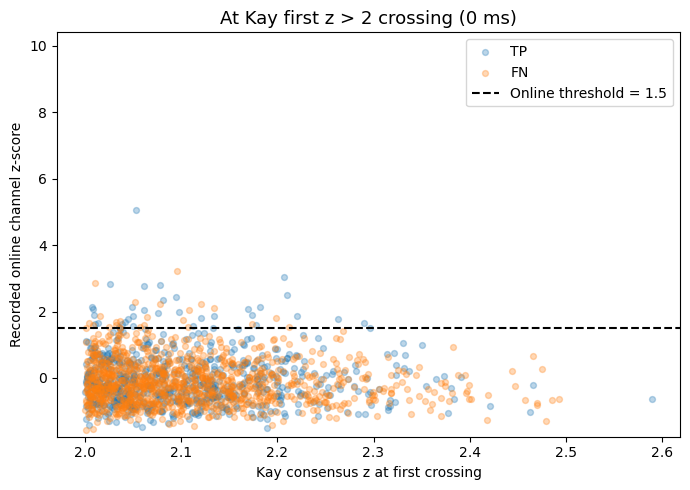

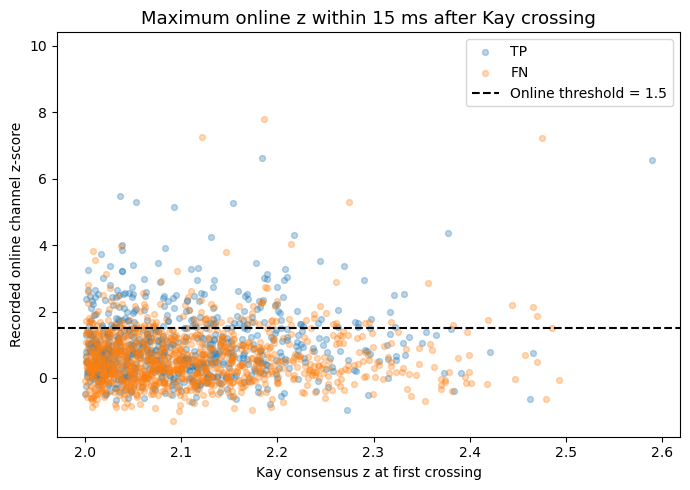

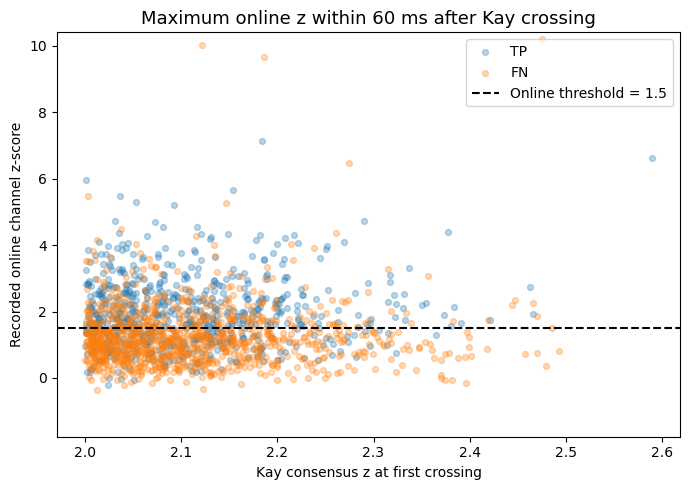

In [47]:
import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# Prepare data
# ------------------------------------------------------------

plot_df = kay_cross_comparison[
    kay_cross_comparison["event_type"].isin(["TP", "FN"])
].copy()

# Merge 15-ms and 60-ms maximum online z-scores
plot_df = plot_df.merge(
    tp_fn_windows[
        ["offline_id", "online_max_z_15ms", "online_max_z_60ms"]
    ],
    on="offline_id",
    how="left",
    validate="many_to_one"
)

# ------------------------------------------------------------
# Define the three plots
# ------------------------------------------------------------

plot_settings = [
    (
        "online_z_102",
        "At Kay first z > 2 crossing (0 ms)"
    ),
    (
        "online_max_z_15ms",
        "Maximum online z within 15 ms after Kay crossing"
    ),
    (
        "online_max_z_60ms",
        "Maximum online z within 60 ms after Kay crossing"
    )
]

# Consistent axis limits across figures
all_y = np.concatenate([
    plot_df[col].dropna().to_numpy()
    for col, _ in plot_settings
])

y_min = min(-1, all_y.min() - 0.2)
y_max = all_y.max() + 0.2

# ------------------------------------------------------------
# Generate three separate figures
# ------------------------------------------------------------

for column, title in plot_settings:

    fig, ax = plt.subplots(figsize=(7, 5))

    for event_type, color in [
        ("TP", "tab:blue"),
        ("FN", "tab:orange")
    ]:

        subset = plot_df[
            plot_df["event_type"] == event_type
        ]

        ax.scatter(
            subset["kay_cross_z"],
            subset[column],
            s=18,
            alpha=0.30,
            color=color,
            label=event_type
        )

    ax.axhline(
        1.5,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="Online threshold = 1.5"
    )

    ax.set_title(title, fontsize=13)
    ax.set_xlabel("Kay consensus z at first crossing")
    ax.set_ylabel("Recorded online channel z-score")

    ax.set_ylim(y_min, y_max)
    ax.legend()

    plt.tight_layout()
    plt.show()

In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. Select offline ripples without an in-interval FIRST laser pulse (FN)
# ============================================================

fn_delay_offline = offline_event_table[
    offline_event_table["event_type"] == "FN"
].copy()

# ============================================================
# 2. Select trains whose FIRST laser pulse was outside all offline ripples
# ============================================================

fn_delay_online = laser_event_table[
    laser_event_table["event_type"] == "FP-like"
].copy()

# Sort timestamps
fn_delay_offline = fn_delay_offline.sort_values("end_time")

fn_delay_online_times = np.sort(
    fn_delay_online["laser_onset"].to_numpy(dtype=float)
)

# ============================================================
# 3. Find first online-only trigger AFTER each FN ripple ends
# ============================================================

fn_delay_end_times = fn_delay_offline[
    "end_time"
].to_numpy(dtype=float)

fn_delay_idx = np.searchsorted(
    fn_delay_online_times,
    fn_delay_end_times,
    side="right"
)

fn_delay_valid = fn_delay_idx < len(fn_delay_online_times)

fn_delay_ms = np.full(
    len(fn_delay_end_times),
    np.nan
)

fn_delay_ms[fn_delay_valid] = (
    fn_delay_online_times[fn_delay_idx[fn_delay_valid]]
    - fn_delay_end_times[fn_delay_valid]
) * 1000

# Store results
fn_delay_results = fn_delay_offline.copy()

fn_delay_results["delay_to_next_online_only_ms"] = fn_delay_ms

# ============================================================
# 4. Summary
# ============================================================

fn_delay_valid_values = fn_delay_ms[np.isfinite(fn_delay_ms)]

print("Total laser-negative offline ripples (FN):", len(fn_delay_results))
print("FN ripples with a later online-only trigger:",
      len(fn_delay_valid_values))

print(
    "Median delay to next online-only trigger:",
    f"{np.median(fn_delay_valid_values):.1f} ms"
)

print(
    "Mean delay:",
    f"{np.mean(fn_delay_valid_values):.1f} ms"
)

for fn_delay_window in [15, 30, 60, 100, 200]:

    fn_delay_percent = (
        np.mean(fn_delay_valid_values <= fn_delay_window) * 100
    )

    print(
        f"Within {fn_delay_window} ms:",
        f"{fn_delay_percent:.1f}%"
    )

Total laser-negative offline ripples (FN): 1066
FN ripples with a later online-only trigger: 1066
Median delay to next online-only trigger: 2075.2 ms
Mean delay: 2826.2 ms
Within 15 ms: 1.8%
Within 30 ms: 2.4%
Within 60 ms: 3.9%
Within 100 ms: 6.0%
Within 200 ms: 9.7%


## Laser and H5 timestamp alignment — secondary diagnostics

The following plots inspect the H5 detector state around actual laser onset. They do **not** reassign the laser-defined TP/FN labels.

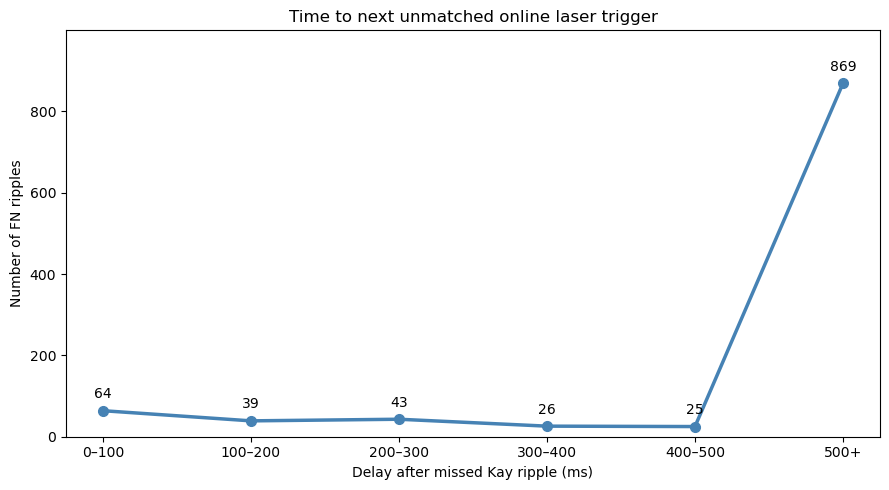

In [49]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Prepare delay data (unique variable names)
# ============================================================

fn_100bin_delays = (
    fn_delay_results["delay_to_next_online_only_ms"]
    .dropna()
    .to_numpy(dtype=float)
)

fn_100bin_delays = fn_100bin_delays[
    np.isfinite(fn_100bin_delays) &
    (fn_100bin_delays >= 0)
]

# ============================================================
# Count events in each delay category
# ============================================================

fn_100bin_edges = [0, 100, 200, 300, 400, 500, np.inf]

fn_100bin_labels = [
    "0–100",
    "100–200",
    "200–300",
    "300–400",
    "400–500",
    "500+"
]

fn_100bin_counts, _ = np.histogram(
    fn_100bin_delays,
    bins=fn_100bin_edges
)

fn_100bin_x = np.arange(len(fn_100bin_labels))

# ============================================================
# Line plot
# ============================================================

fn_100bin_fig, fn_100bin_ax = plt.subplots(figsize=(9, 5))

fn_100bin_ax.plot(
    fn_100bin_x,
    fn_100bin_counts,
    marker="o",
    markersize=7,
    linewidth=2.5,
    color="steelblue"
)

# Add event counts above each point
for fn_100bin_i, fn_100bin_count in enumerate(fn_100bin_counts):
    fn_100bin_ax.annotate(
        str(fn_100bin_count),
        (fn_100bin_i, fn_100bin_count),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center"
    )

fn_100bin_ax.set_xticks(fn_100bin_x)
fn_100bin_ax.set_xticklabels(fn_100bin_labels)

fn_100bin_ax.set_xlabel(
    "Delay after missed Kay ripple (ms)"
)

fn_100bin_ax.set_ylabel("Number of FN ripples")

fn_100bin_ax.set_title(
    "Time to next unmatched online laser trigger"
)

fn_100bin_ax.set_ylim(
    0,
    max(fn_100bin_counts) * 1.15
)

plt.tight_layout()
plt.show()

Total offline FN events: 1066
Events using start-time fallback: 0



OFFLINE FN: H5 DETECTION AND LASER LOCKOUT

Total offline FN ripples: 1066
Lockout duration: 100 ms
Lockout reference: first_pulse

Classification:
             Category  Count  Percentage
    H5 True + Lockout     52         4.9
 H5 True + No lockout     99         9.3
   H5 False + Lockout     39         3.7
H5 False + No lockout    876        82.2

Additional summaries:
FN with lockout at Kay crossing: 91 (8.5%)
FN with any H5 True: 151 (14.2%)
FN with H5 True during lockout: 34 (3.2%)


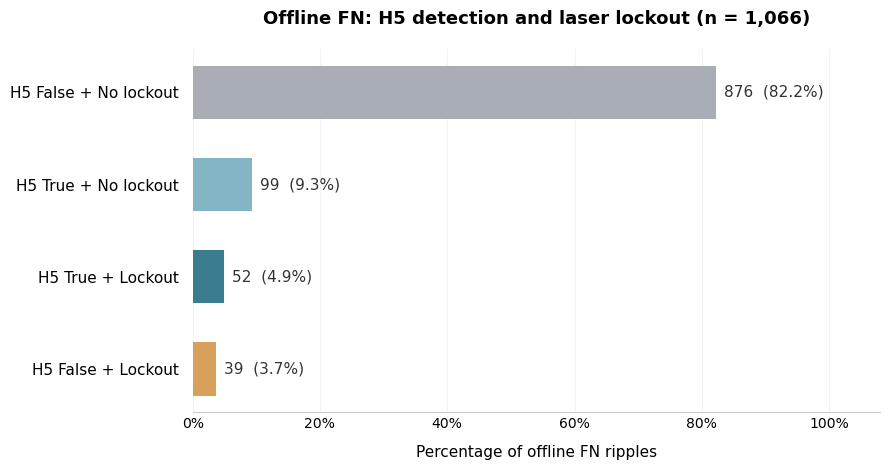

,start_time,end_time,kay_cross_time,has_h5_detection,in_lockout,h5_true_during_lockout,category
id,,,,,,,
0,1.785621e+09,1.785621e+09,1.785621e+09,False,False,False,H5 False + No lockout
2,1.785621e+09,1.785621e+09,1.785621e+09,False,False,False,H5 False + No lockout
4,1.785621e+09,1.785621e+09,1.785621e+09,False,False,False,H5 False + No lockout
5,1.785621e+09,1.785621e+09,1.785621e+09,False,False,False,H5 False + No lockout
6,1.785621e+09,1.785621e+09,1.785621e+09,False,False,False,H5 False + No lockout
8,1.785621e+09,1.785621e+09,1.785621e+09,False,False,False,H5 False + No lockout
11,1.785621e+09,1.785621e+09,1.785621e+09,False,False,False,H5 False + No lockout
15,1.785621e+09,1.785621e+09,1.785621e+09,False,False,False,H5 False + No lockout
17,1.785621e+09,1.785621e+09,1.785621e+09,True,True,True,H5 True + Lockout


In [50]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. SETTINGS
# ============================================================

LOCKOUT_MS = 100
LOCKOUT_FROM = "first_pulse"

# Assumption:
# Lockout begins at the first laser pulse and lasts 100 ms.
# If lockout actually begins after the last pulse, change
# LOCKOUT_FROM to "last_pulse".

# ============================================================
# 2. RECONSTRUCT LASER LOCKOUT INTERVALS
# ============================================================

# First and last pulse of each laser train
train_first = online_trains[:, 0].astype(float)
train_last = online_trains[:, -1].astype(float)

if LOCKOUT_FROM == "first_pulse":
    lockout_end = np.maximum(
        train_last,
        train_first + LOCKOUT_MS / 1000
    )

elif LOCKOUT_FROM == "last_pulse":
    lockout_end = train_last + LOCKOUT_MS / 1000

else:
    raise ValueError("Invalid LOCKOUT_FROM")

# Handle possible overlapping lockout intervals
lockout_end_max = np.maximum.accumulate(lockout_end)

def is_locked_at(times):
    times = np.asarray(times, dtype=float)

    idx = np.searchsorted(
        train_first, times, side="right"
    ) - 1

    result = np.zeros(len(times), dtype=bool)

    valid = idx >= 0

    result[valid] = (
        times[valid] <= lockout_end_max[idx[valid]]
    )

    return result

# ============================================================
# 3. SELECT OFFLINE FN EVENTS
# ============================================================

fn_lockout = offline_event_table[
    offline_event_table["event_type"] == "FN"
].copy()

# Retrieve Kay first threshold-crossing timestamps
crossing_lookup = (
    kay_cross_comparison
    .set_index("offline_id")["kay_cross_time"]
)

fn_lockout["kay_cross_time"] = (
    fn_lockout.index.to_series().map(crossing_lookup)
)

# Use offline start if Kay crossing is unavailable
missing_cross = fn_lockout["kay_cross_time"].isna()

fn_lockout["reference_time"] = (
    fn_lockout["kay_cross_time"]
    .fillna(fn_lockout["start_time"])
)

# Was the system locked at the Kay crossing?
fn_lockout["in_lockout"] = is_locked_at(
    fn_lockout["reference_time"].to_numpy(dtype=float)
)

print("Total offline FN events:", len(fn_lockout))
print("Events using start-time fallback:", missing_cross.sum())

# ============================================================
# 4. CHECK H5 rip_detected=True DURING EACH FN RIPPLE
# ============================================================

# Continuous H5 timestamps and detection flags
h5_times = online_overlap[
    "timestamp"
].to_numpy(dtype=float)

h5_detected = (
    online_overlap["detected"]
    .fillna(False)
    .astype(bool)
    .to_numpy()
)

fn_starts = fn_lockout[
    "start_time"
].to_numpy(dtype=float)

fn_ends = fn_lockout[
    "end_time"
].to_numpy(dtype=float)

# Find all H5 samples inside each offline ripple
left = np.searchsorted(
    h5_times, fn_starts, side="left"
)

right = np.searchsorted(
    h5_times, fn_ends, side="right"
)

# Check data coverage
if np.any(right == left):
    raise ValueError(
        "Some FN ripples contain no H5 samples. "
        "Check timestamp alignment."
    )

# Cumulative sum of H5 True samples
detected_cumsum = np.r_[
    0, np.cumsum(h5_detected, dtype=np.int64)
]

# Whether ANY H5 True sample overlaps each ripple
fn_lockout["has_h5_detection"] = (
    detected_cumsum[right] -
    detected_cumsum[left]
) > 0

# ============================================================
# 5. CHECK WHETHER H5 TRUE OCCURRED DURING LOCKOUT
# ============================================================

# Is each H5 sample inside a reconstructed lockout?
h5_locked = is_locked_at(h5_times)

# Samples where H5 True and laser lockout coincide
h5_true_and_locked = h5_detected & h5_locked

locked_cumsum = np.r_[
    0, np.cumsum(h5_true_and_locked, dtype=np.int64)
]

fn_lockout["h5_true_during_lockout"] = (
    locked_cumsum[right] -
    locked_cumsum[left]
) > 0

# ============================================================
# 6. CLASSIFY FN EVENTS INTO FOUR CATEGORIES
# ============================================================

h5 = fn_lockout["has_h5_detection"]
lock = fn_lockout["in_lockout"]

categories = {
    "H5 True + Lockout": h5 & lock,
    "H5 True + No lockout": h5 & ~lock,
    "H5 False + Lockout": ~h5 & lock,
    "H5 False + No lockout": ~h5 & ~lock
}

total_fn = len(fn_lockout)

if total_fn == 0:
    raise ValueError("No offline FN events found.")

summary = pd.DataFrame([
    {
        "Category": name,
        "Count": int(mask.sum()),
        "Percentage": 100 * mask.sum() / total_fn
    }
    for name, mask in categories.items()
])

# ============================================================
# 7. PRINT RESULTS
# ============================================================

print("\n" + "=" * 55)
print("OFFLINE FN: H5 DETECTION AND LASER LOCKOUT")
print("=" * 55)

print(f"\nTotal offline FN ripples: {total_fn}")
print(f"Lockout duration: {LOCKOUT_MS} ms")
print(f"Lockout reference: {LOCKOUT_FROM}")

print("\nClassification:")
print(
    summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.1f}"
    )
)

n_lockout = int(lock.sum())
n_h5 = int(h5.sum())
n_h5_locked = int(
    fn_lockout["h5_true_during_lockout"].sum()
)

print("\nAdditional summaries:")

print(
    f"FN with lockout at Kay crossing: "
    f"{n_lockout} ({100*n_lockout/total_fn:.1f}%)"
)

print(
    f"FN with any H5 True: "
    f"{n_h5} ({100*n_h5/total_fn:.1f}%)"
)

print(
    f"FN with H5 True during lockout: "
    f"{n_h5_locked} "
    f"({100*n_h5_locked/total_fn:.1f}%)"
)

# ============================================================
# 8. STACKED BAR PLOT
# ============================================================


# ============================================================
# 8. BAR PLOT — FN CLASSIFICATION
# ============================================================


# ============================================================
# 8. CLEAN BAR PLOT — FN CLASSIFICATION
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# Order categories from most to least frequent
plot_df = summary.sort_values("Percentage", ascending=True).copy()

# Shorter labels
label_map = {
    "H5 True + Lockout": "H5 True + Lockout",
    "H5 True + No lockout": "H5 True + No lockout",
    "H5 False + Lockout": "H5 False + Lockout",
    "H5 False + No lockout": "H5 False + No lockout"
}

# Muted, publication-style colors
color_map = {
    "H5 True + Lockout": "#3A7D91",
    "H5 True + No lockout": "#83B5C4",
    "H5 False + Lockout": "#D7A05B",
    "H5 False + No lockout": "#A9AEB6"
}

fig, ax = plt.subplots(figsize=(9, 4.8))

y = np.arange(len(plot_df))

bars = ax.barh(
    y,
    plot_df["Percentage"],
    height=0.58,
    color=[color_map[c] for c in plot_df["Category"]],
    edgecolor="none"
)

# Counts and percentages
for bar, (_, row) in zip(bars, plot_df.iterrows()):
    ax.text(
        bar.get_width() + 1.3,
        bar.get_y() + bar.get_height() / 2,
        f'{int(row["Count"]):,}  ({row["Percentage"]:.1f}%)',
        va="center",
        ha="left",
        fontsize=11,
        color="#333333"
    )

ax.set_yticks(y)
ax.set_yticklabels(
    [label_map[c] for c in plot_df["Category"]],
    fontsize=11
)

ax.set_xlim(0, 108)
ax.set_xticks(np.arange(0, 101, 20))
ax.set_xticklabels(
    [f"{v}%" for v in np.arange(0, 101, 20)]
)

ax.set_xlabel(
    "Percentage of offline FN ripples",
    fontsize=11,
    labelpad=10
)

ax.set_title(
    f"Offline FN: H5 detection and laser lockout (n = {total_fn:,})",
    fontsize=13,
    fontweight="semibold",
    pad=18
)

# Subtle gridlines
ax.set_axisbelow(True)
ax.grid(
    axis="x",
    linestyle="-",
    alpha=0.15,
    linewidth=0.8
)

# Remove unnecessary borders
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.spines["bottom"].set_color("#CCCCCC")

ax.tick_params(axis="y", length=0, pad=10)
ax.tick_params(axis="x", length=0, labelsize=10)

plt.tight_layout()
plt.show()

# ============================================================
# 9. SAVE EVENT-LEVEL CLASSIFICATION IN DATAFRAME
# ============================================================

fn_lockout["category"] = np.select(
    list(categories.values()),
    list(categories.keys()),
    default="Unclassified"
)

display(fn_lockout[[
    "start_time",
    "end_time",
    "kay_cross_time",
    "has_h5_detection",
    "in_lockout",
    "h5_true_during_lockout",
    "category"
]].head(20))


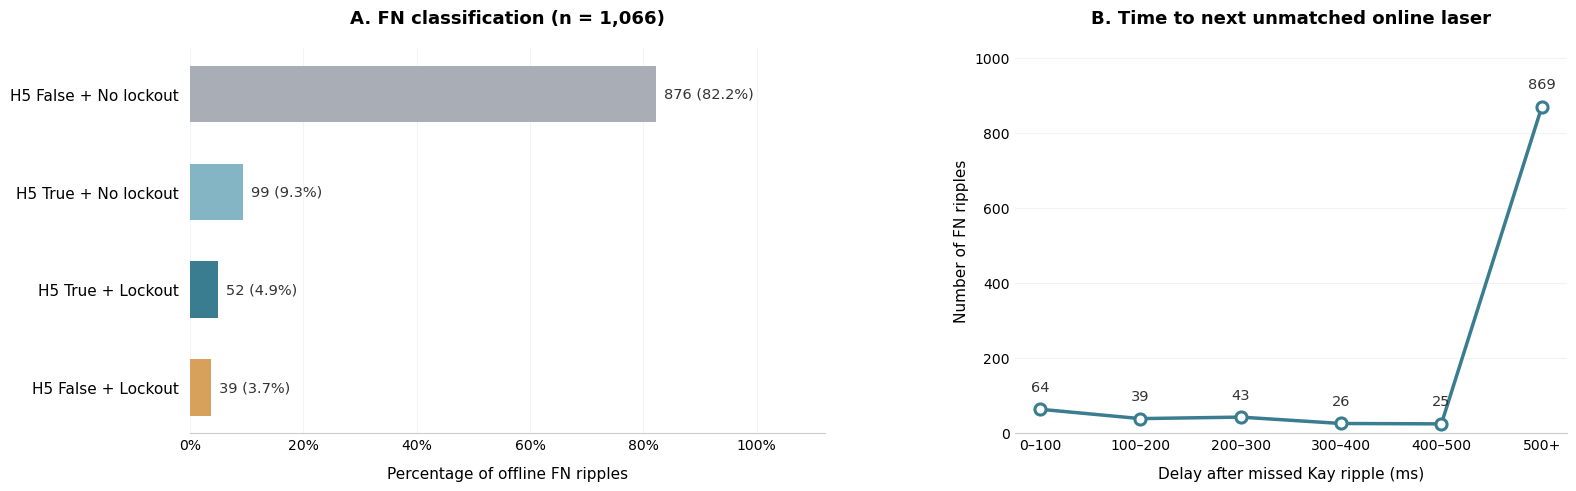

In [51]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# PANEL A: FN classification
# ============================================================

plot_df = summary.sort_values(
    "Percentage", ascending=True
).copy()

color_map = {
    "H5 True + Lockout": "#3A7D91",
    "H5 True + No lockout": "#83B5C4",
    "H5 False + Lockout": "#D7A05B",
    "H5 False + No lockout": "#A9AEB6"
}

# ============================================================
# PANEL B: Delay to next unmatched online laser trigger
# ============================================================

fn_100bin_delays = (
    fn_delay_results["delay_to_next_online_only_ms"]
    .dropna()
    .to_numpy(dtype=float)
)

fn_100bin_delays = fn_100bin_delays[
    np.isfinite(fn_100bin_delays) &
    (fn_100bin_delays >= 0)
]

fn_100bin_edges = [0, 100, 200, 300, 400, 500, np.inf]

fn_100bin_labels = [
    "0–100",
    "100–200",
    "200–300",
    "300–400",
    "400–500",
    "500+"
]

fn_100bin_counts, _ = np.histogram(
    fn_100bin_delays,
    bins=fn_100bin_edges
)

fn_100bin_x = np.arange(len(fn_100bin_labels))

# ============================================================
# CREATE TWO-PANEL FIGURE
# ============================================================

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(17, 5.5),
    gridspec_kw={"width_ratios": [1.15, 1]}
)

# ============================================================
# PANEL A — H5 detection vs. lockout
# ============================================================

y = np.arange(len(plot_df))

bars = ax1.barh(
    y,
    plot_df["Percentage"],
    height=0.58,
    color=[color_map[c] for c in plot_df["Category"]],
    edgecolor="none"
)

for bar, (_, row) in zip(bars, plot_df.iterrows()):
    ax1.text(
        bar.get_width() + 1.5,
        bar.get_y() + bar.get_height() / 2,
        f'{int(row["Count"]):,} ({row["Percentage"]:.1f}%)',
        ha="left",
        va="center",
        fontsize=10.5,
        color="#333333"
    )

ax1.set_yticks(y)
ax1.set_yticklabels(
    plot_df["Category"],
    fontsize=11
)

ax1.set_xlim(0, 112)
ax1.set_xticks(np.arange(0, 101, 20))
ax1.set_xticklabels(
    [f"{v}%" for v in np.arange(0, 101, 20)]
)

ax1.set_xlabel(
    "Percentage of offline FN ripples",
    fontsize=11,
    labelpad=10
)

ax1.set_title(
    f"A. FN classification (n = {total_fn:,})",
    fontsize=13,
    fontweight="semibold",
    pad=18
)

ax1.set_axisbelow(True)
ax1.grid(axis="x", alpha=0.15, linewidth=0.8)

ax1.tick_params(axis="y", length=0, pad=8)
ax1.tick_params(axis="x", length=0, labelsize=10)

# ============================================================
# PANEL B — Delay to next unmatched laser
# ============================================================

ax2.plot(
    fn_100bin_x,
    fn_100bin_counts,
    marker="o",
    markersize=8,
    linewidth=2.5,
    color="#3A7D91",
    markerfacecolor="white",
    markeredgewidth=2.2,
    markeredgecolor="#3A7D91"
)

# Counts above points
for i, count in enumerate(fn_100bin_counts):
    ax2.annotate(
        f"{count:,}",
        (i, count),
        xytext=(0, 11),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10.5,
        color="#333333"
    )

ax2.set_xticks(fn_100bin_x)
ax2.set_xticklabels(
    fn_100bin_labels,
    fontsize=10
)

ax2.set_xlabel(
    "Delay after missed Kay ripple (ms)",
    fontsize=11,
    labelpad=10
)

ax2.set_ylabel(
    "Number of FN ripples",
    fontsize=11
)

ax2.set_title(
    "B. Time to next unmatched online laser",
    fontsize=13,
    fontweight="semibold",
    pad=18
)

ax2.set_ylim(
    0,
    max(fn_100bin_counts.max() * 1.18, 1)
)

ax2.set_axisbelow(True)
ax2.grid(axis="y", alpha=0.15, linewidth=0.8)

ax2.tick_params(axis="both", length=0, labelsize=10)

# ============================================================
# SHARED STYLING
# ============================================================

for ax in [ax1, ax2]:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_color("#CCCCCC")

plt.subplots_adjust(
    left=0.16,
    right=0.97,
    bottom=0.16,
    top=0.86,
    wspace=0.32
)

plt.show()


Median timestamp difference (ms): 0.17940998077392578
Online channel above 1.5 at laser onset: 52.4%
Online channel below/equal 1.5 at laser onset: 47.6%


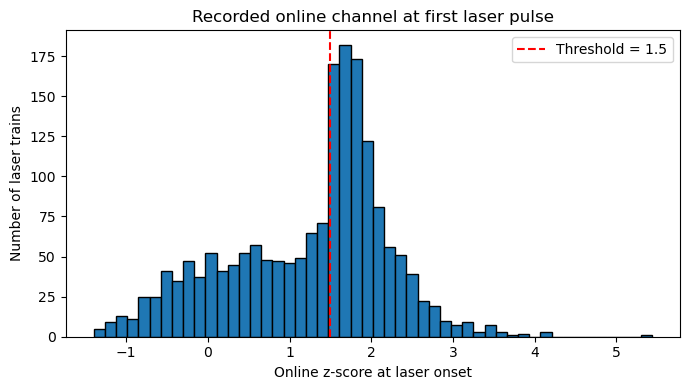

In [52]:
# Actual first laser pulse of each train, already computed in Setup 2.
laser_onsets = online_trains[:, 0].astype(float)
online_times = online_overlap['timestamp'].to_numpy(dtype=float)
online_z = online_overlap['z'].to_numpy(dtype=float)
# Find nearest online sample to each laser onset
idx = np.searchsorted(online_times, laser_onsets)
idx = np.clip(idx, 1, len(online_times) - 1)
left = idx - 1
right = idx
nearest = np.where(
    np.abs(online_times[left] - laser_onsets)
    <= np.abs(online_times[right] - laser_onsets),
    left, right
)
time_error_ms = (online_times[nearest] - laser_onsets) * 1000
laser_z = online_z[nearest]
print('Median timestamp difference (ms):', np.median(np.abs(time_error_ms)))
print('Online channel above 1.5 at laser onset:',
      f'{np.mean(laser_z > 1.5)*100:.1f}%')
print('Online channel below/equal 1.5 at laser onset:',
      f'{np.mean(laser_z <= 1.5)*100:.1f}%')
plt.figure(figsize=(7, 4))
plt.hist(laser_z[np.isfinite(laser_z)], bins=50, edgecolor='black')
plt.axvline(1.5, color='red', linestyle='--', label='Threshold = 1.5')
plt.xlabel('Online z-score at laser onset')
plt.ylabel('Number of laser trains')
plt.title('Recorded online channel at first laser pulse')
plt.legend(); plt.tight_layout(); plt.show()

In [53]:
import numpy as np
import pandas as pd

times = online_overlap["timestamp"].to_numpy()
detected = online_overlap["detected"].fillna(False).astype(bool).to_numpy()

laser_onsets = online_trains[:, 0]

results = []

for window_ms in [0, 10, 20, 50, 100]:

    matches = []

    for laser_time in laser_onsets:

        if window_ms == 0:
            # Nearest available H5 sample
            i = np.searchsorted(times, laser_time)
            i = np.clip(i, 1, len(times) - 1)

            nearest = (
                i - 1
                if abs(times[i-1] - laser_time)
                <= abs(times[i] - laser_time)
                else i
            )
            matches.append(detected[nearest])

        else:
            # Was detected True at any time before laser?
            left = np.searchsorted(
                times, laser_time - window_ms / 1000
            )
            right = np.searchsorted(
                times, laser_time, side="right"
            )

            matches.append(
                detected[left:right].any()
            )

    results.append({
        "Window before laser (ms)": window_ms,
        "Laser with rip_detected True (%)":
            np.mean(matches) * 100
    })

display(pd.DataFrame(results))

,Window before laser (ms),Laser with rip_detected True (%)
0,0,75.757576
1,10,93.939394
2,20,95.061728
3,50,98.484848
4,100,100.000000


## Optional H5 detector-onset diagnostic (separate from laser-first-pulse event classification)

This section examines H5-detected onsets and Kay z. It uses a different event population from the laser-first-pulse TP/FN analysis; avoid interpreting these figures as stimulation success/failure.

In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

online_times = online_overlap["timestamp"].to_numpy(dtype=float)
online_z = online_overlap["z"].to_numpy(dtype=float)

detected = (
    online_overlap["detected"]
    .fillna(False)
    .astype(bool)
    .to_numpy()
)

# First True sample of each consecutive detection episode
onset_idx = np.flatnonzero(
    detected & ~np.r_[False, detected[:-1]]
)

online_onset_times = online_times[onset_idx]
online_onset_z = online_z[onset_idx]

online_detection_df = pd.DataFrame({
    "online_onset_time": online_onset_times,
    "online_z_at_onset": online_onset_z
})

print("Total online detection episodes:", len(online_detection_df))
display(online_detection_df.head())

Total online detection episodes: 5546


,online_onset_time,online_z_at_onset
0,1.785621e+09,0.859630
1,1.785621e+09,1.604513
2,1.785621e+09,0.926087
3,1.785621e+09,2.087556
4,1.785621e+09,1.292539


In [55]:
import numpy as np
import pandas as pd

online_times = online_overlap["timestamp"].to_numpy(dtype=float)
online_z = online_overlap["z"].to_numpy(dtype=float)

detected = (
    online_overlap["detected"]
    .fillna(False)
    .astype(bool)
    .to_numpy()
)

# Find False -> True transitions
onset_idx = np.flatnonzero(
    detected & ~np.r_[False, detected[:-1]]
)

online_onset_times = online_times[onset_idx]
online_z_at_onset = online_z[onset_idx]

print("Total online detection onsets:", len(onset_idx))
print("Median online z at onset:", np.nanmedian(online_z_at_onset))

Total online detection onsets: 5546
Median online z at onset: 1.5212453496126268


In [56]:
kay_t = kay_z.index.to_numpy(dtype=float).ravel()
kay_values = np.asarray(kay_z, dtype=float).ravel()

print("Kay timestamps:", kay_t.shape)
print("Kay z-scores:", kay_values.shape)

# Check dimensions match
assert len(kay_t) == len(kay_values)

# Remove invalid values
valid = np.isfinite(kay_t) & np.isfinite(kay_values)

kay_t = kay_t[valid]
kay_values = kay_values[valid]

# Sort timestamps
order = np.argsort(kay_t)

kay_t = kay_t[order]
kay_values = kay_values[order]

Kay timestamps: (2401558,)
Kay z-scores: (2401558,)


In [57]:
# Find the nearest Kay timestamp for each online detection
idx = np.searchsorted(kay_t, online_onset_times)
idx = np.clip(idx, 1, len(kay_t) - 1)

left = idx - 1
right = idx

nearest = np.where(
    np.abs(kay_t[left] - online_onset_times)
    <= np.abs(kay_t[right] - online_onset_times),
    left,
    right
)

kay_z_at_onset = kay_values[nearest].copy()

# Check temporal proximity
time_error_ms = (
    kay_t[nearest] - online_onset_times
) * 1000

# Exclude samples more than 2 ms away
kay_z_at_onset[np.abs(time_error_ms) > 2] = np.nan

print(
    "Median timestamp difference (ms):",
    np.median(np.abs(time_error_ms))
)

Median timestamp difference (ms): 0.2372264862060547


In [58]:
online_detection_comparison = pd.DataFrame({
    "online_onset_time": online_onset_times,
    "online_z_at_onset": online_z_at_onset,
    "kay_z_at_onset": kay_z_at_onset,
    "kay_time_error_ms": time_error_ms
})

valid_events = online_detection_comparison.dropna(
    subset=["online_z_at_onset", "kay_z_at_onset"]
)

print("Total online detection onsets:", len(online_detection_comparison))
print("Valid matched events:", len(valid_events))

print(
    "Median ONLINE z at detection onset:",
    valid_events["online_z_at_onset"].median()
)

print(
    "Median OFFLINE Kay z at same time:",
    valid_events["kay_z_at_onset"].median()
)

print(
    "Kay z > 2 at online detection onset:",
    f"{(valid_events['kay_z_at_onset'] > 2).mean() * 100:.1f}%"
)

Total online detection onsets: 5546
Valid matched events: 5543
Median ONLINE z at detection onset: 1.5212480501175758
Median OFFLINE Kay z at same time: 0.7964066863056958
Kay z > 2 at online detection onset: 24.0%


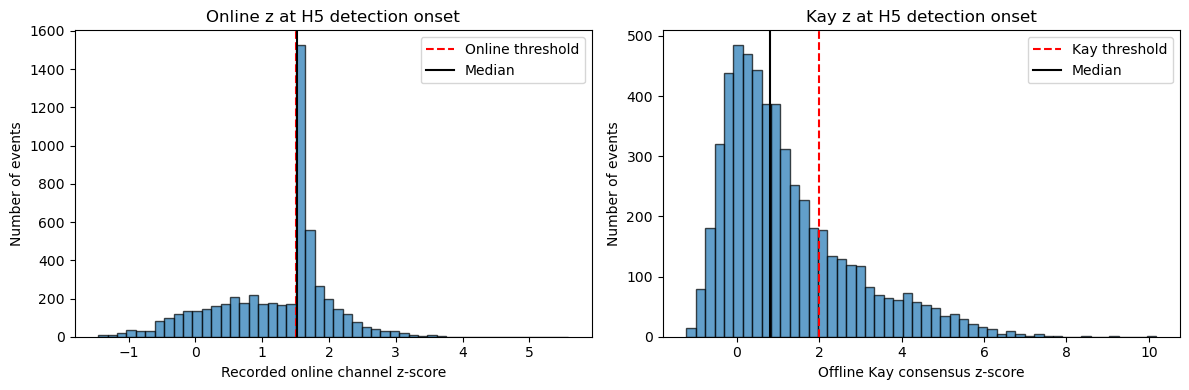

In [59]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(
    valid_events["online_z_at_onset"],
    bins=50,
    alpha=0.7,
    edgecolor="black"
)
axes[0].axvline(1.5, color="red", linestyle="--", label="Online threshold")
axes[0].axvline(
    valid_events["online_z_at_onset"].median(),
    color="black", label="Median"
)
axes[0].set_title("Online z at H5 detection onset")
axes[0].set_xlabel("Recorded online channel z-score")
axes[0].set_ylabel("Number of events")
axes[0].legend()

axes[1].hist(
    valid_events["kay_z_at_onset"],
    bins=50,
    alpha=0.7,
    edgecolor="black"
)
axes[1].axvline(2, color="red", linestyle="--", label="Kay threshold")
axes[1].axvline(
    valid_events["kay_z_at_onset"].median(),
    color="black", label="Median"
)
axes[1].set_title("Kay z at H5 detection onset")
axes[1].set_xlabel("Offline Kay consensus z-score")
axes[1].set_ylabel("Number of events")
axes[1].legend()

plt.tight_layout()
plt.show()

## Complementary analysis — what is Kay doing at the first laser pulse of each train?

`laser_comparison_df` below is *laser-centered*. Labels are copied from the **same canonical laser_event_table** created in Setup 4. Comparisons report recorded online H5 channel z and offline Kay consensus z at the first laser pulse, with a nearest-sample tolerance of 2 ms.

In [60]:
import numpy as np
import pandas as pd

# First pulse of each laser train
laser_compare_times = np.asarray(
    online_trains[:, 0], dtype=float
)

# Continuous online trace
laser_online_t = online_overlap["timestamp"].to_numpy(dtype=float)
laser_online_z = online_overlap["z"].to_numpy(dtype=float)

# Continuous offline Kay consensus trace
laser_kay_t = np.asarray(kay_t, dtype=float).ravel()
laser_kay_z = np.asarray(kay_values, dtype=float).ravel()

# Helper: nearest sample with timestamp tolerance
def laser_nearest_z(times, values, targets, tolerance_ms=2):
    times = np.asarray(times, dtype=float).ravel()
    values = np.asarray(values, dtype=float).ravel()
    targets = np.asarray(targets, dtype=float).ravel()

    assert len(times) == len(values)
    assert np.all(np.diff(times) >= 0), "Timestamps must be sorted"

    idx = np.searchsorted(times, targets)
    if len(times) < 2:
        raise ValueError("Expected at least two trace samples")
    idx = np.clip(idx, 1, len(times) - 1)

    left = idx - 1
    right = idx

    nearest = np.where(
        np.abs(times[left] - targets) <=
        np.abs(times[right] - targets),
        left, right
    )

    matched_z = values[nearest].copy()
    error_ms = (times[nearest] - targets) * 1000

    matched_z[
        np.abs(error_ms) > tolerance_ms
    ] = np.nan

    return matched_z, error_ms


# Online z at first laser pulse
laser_online_z_at_onset, laser_online_error_ms = laser_nearest_z(
    laser_online_t,
    laser_online_z,
    laser_compare_times
)

# Offline Kay z at the same laser pulse
laser_kay_z_at_onset, laser_kay_error_ms = laser_nearest_z(
    laser_kay_t,
    laser_kay_z,
    laser_compare_times
)

laser_comparison_df = pd.DataFrame({
    "laser_onset": laser_compare_times,
    "online_z": laser_online_z_at_onset,
    "kay_z": laser_kay_z_at_onset,
    "online_time_error_ms": laser_online_error_ms,
    "kay_time_error_ms": laser_kay_error_ms
})

print("Total laser trains:", len(laser_comparison_df))
print("Valid online z:", laser_comparison_df["online_z"].notna().sum())
print("Valid Kay z:", laser_comparison_df["kay_z"].notna().sum())

Total laser trains: 1782
Valid online z: 1782
Valid Kay z: 1781


In [61]:
# Use the canonical laser-first-pulse matching computed in Setup 4.
# DO NOT recompute labels by train overlap or nearest offline start here.
if len(laser_comparison_df) != len(laser_event_table):
    raise ValueError('Laser comparison table and laser event table have different lengths')
if not np.allclose(laser_comparison_df['laser_onset'].to_numpy(),
                   laser_event_table['laser_onset'].to_numpy(), rtol=0, atol=1e-6):
    raise ValueError('First laser pulse times in comparison and label tables differ')
laser_comparison_df['event_type'] = laser_event_table['event_type'].to_numpy()
laser_comparison_df['has_offline_match'] = laser_event_table['has_offline_match'].to_numpy()
laser_comparison_df['matched_offline_id'] = laser_event_table['matched_offline_id'].to_numpy()
print('Laser-centered first-pulse outcomes:')
print(laser_comparison_df['event_type'].value_counts())

Laser-centered first-pulse outcomes:
event_type
FP-like    1100
TP          682
Name: count, dtype: int64


In [62]:
laser_valid_comparison = laser_comparison_df.dropna(
    subset=["online_z", "kay_z"]
)

laser_median_summary = (
    laser_valid_comparison
    .groupby("event_type")
    .agg(
        n_events=("laser_onset", "count"),
        median_online_z=("online_z", "median"),
        median_kay_z=("kay_z", "median"),
        mean_online_z=("online_z", "mean"),
        mean_kay_z=("kay_z", "mean"),
        kay_above_2_percent=(
            "kay_z",
            lambda x: (x > 2).mean() * 100
        )
    )
)

display(laser_median_summary)

print("\nOverall medians:")
print(
    "Online z:",
    laser_valid_comparison["online_z"].median()
)
print(
    "Offline Kay z:",
    laser_valid_comparison["kay_z"].median()
)

,n_events,median_online_z,median_kay_z,mean_online_z,mean_kay_z,kay_above_2_percent
event_type,,,,,,
FP-like,1099,1.479404,0.166354,1.131108,0.365179,5.277525
TP,682,1.630440,2.874716,1.413441,2.982855,72.873900



Overall medians:
Online z: 1.542477700290452
Offline Kay z: 0.971019688305262


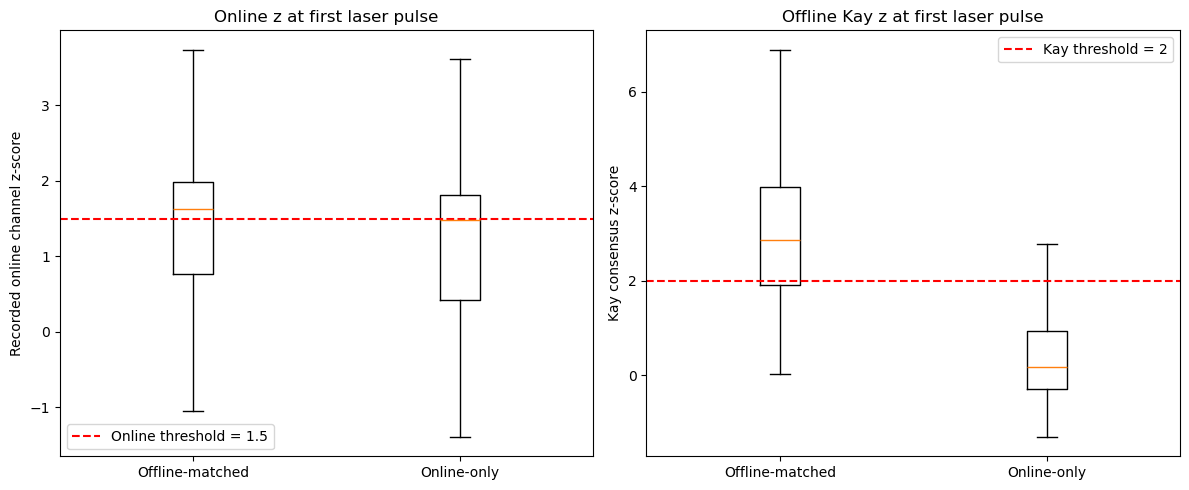

In [63]:
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# Prepare data
# ============================================================

clean_box_df = laser_comparison_df.copy()

clean_box_df["offline_status"] = clean_box_df["event_type"].map({
    "TP": "Offline-matched",
    "FP-like": "Online-only"
})

clean_box_df = clean_box_df.dropna(
    subset=["online_z", "kay_z", "offline_status"]
)

clean_box_groups = ["Offline-matched", "Online-only"]

# ============================================================
# Create figure
# ============================================================

clean_box_fig, clean_box_axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

# LEFT: Online z-score
clean_box_online = [
    clean_box_df.loc[
        clean_box_df["offline_status"] == group,
        "online_z"
    ].to_numpy()
    for group in clean_box_groups
]

clean_box_axes[0].boxplot(
    clean_box_online,
    tick_labels=clean_box_groups,
    showfliers=False
)

clean_box_axes[0].axhline(
    1.5,
    color="red",
    linestyle="--",
    label="Online threshold = 1.5"
)

clean_box_axes[0].set_title("Online z at first laser pulse")
clean_box_axes[0].set_ylabel("Recorded online channel z-score")
clean_box_axes[0].legend()

# RIGHT: Offline Kay z-score
clean_box_kay = [
    clean_box_df.loc[
        clean_box_df["offline_status"] == group,
        "kay_z"
    ].to_numpy()
    for group in clean_box_groups
]

clean_box_axes[1].boxplot(
    clean_box_kay,
    tick_labels=clean_box_groups,
    showfliers=False
)

clean_box_axes[1].axhline(
    2,
    color="red",
    linestyle="--",
    label="Kay threshold = 2"
)

clean_box_axes[1].set_title("Offline Kay z at first laser pulse")
clean_box_axes[1].set_ylabel("Kay consensus z-score")
clean_box_axes[1].legend()

plt.tight_layout()
plt.show()

Total laser trains included: 1782
group
Online-only        1100
Offline-matched     682
Name: count, dtype: int64


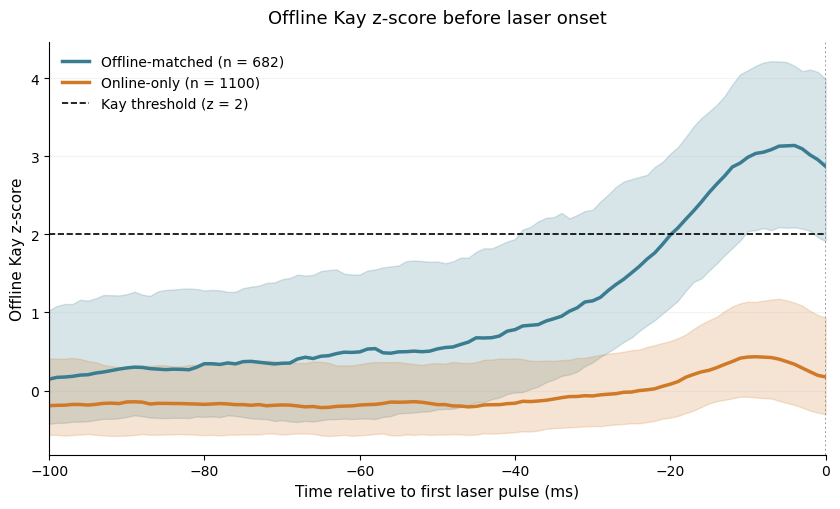

In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# SETTINGS
# ============================================================

PRE_MS = 100          # look 100 ms before first laser pulse
POST_MS = 0           # keep at 0 if you only want the pre-laser window
STEP_MS = 1           # interpolation grid in ms

# ============================================================
# CHECK REQUIRED VARIABLES
# ============================================================

required_vars = ["laser_event_table", "kay_t", "kay_values", "online_trains"]
for v in required_vars:
    if v not in globals():
        raise ValueError(f"Required variable '{v}' not found.")

# ============================================================
# PREPARE LASER LABELS
# ============================================================

laser_onsets = np.asarray(online_trains[:, 0], dtype=float)

if len(laser_event_table) != len(laser_onsets):
    raise ValueError("laser_event_table and online_trains have different lengths")

if not np.allclose(
    laser_event_table["laser_onset"].to_numpy(dtype=float),
    laser_onsets,
    rtol=0,
    atol=1e-6
):
    raise ValueError("laser_event_table laser_onset does not match online_trains first pulse times")

# Use canonical labels from your notebook:
# TP      -> offline-matched
# FP-like -> online-only
group_map = {
    "TP": "Offline-matched",
    "FP-like": "Online-only"
}

plot_labels = laser_event_table["event_type"].map(group_map)

valid_group_mask = plot_labels.notna().to_numpy()

plot_onsets = laser_event_table.loc[valid_group_mask, "laser_onset"].to_numpy(dtype=float)
plot_groups = plot_labels.loc[valid_group_mask].to_numpy()

# ============================================================
# PREPARE KAY TRACE
# ============================================================

kay_t_use = np.asarray(kay_t, dtype=float).ravel()
kay_z_use = np.asarray(kay_values, dtype=float).ravel()

valid = np.isfinite(kay_t_use) & np.isfinite(kay_z_use)
kay_t_use = kay_t_use[valid]
kay_z_use = kay_z_use[valid]

order = np.argsort(kay_t_use)
kay_t_use = kay_t_use[order]
kay_z_use = kay_z_use[order]

if np.any(np.diff(kay_t_use) < 0):
    raise ValueError("Kay timestamps are not sorted")

# ============================================================
# BUILD RELATIVE TIME GRID
# ============================================================

rel_ms = np.arange(-PRE_MS, POST_MS + STEP_MS, STEP_MS)
rel_s = rel_ms / 1000.0

# ============================================================
# INTERPOLATE KAY Z AROUND EACH LASER ONSET
# ============================================================

def extract_aligned_trace(trace_t, trace_z, onset_time, rel_s):
    target_t = onset_time + rel_s

    # Only keep targets within the recorded trace range
    in_range = (
        (target_t >= trace_t[0]) &
        (target_t <= trace_t[-1])
    )

    out = np.full(len(rel_s), np.nan, dtype=float)

    if np.any(in_range):
        out[in_range] = np.interp(
            target_t[in_range],
            trace_t,
            trace_z
        )

    return out

aligned_traces = np.vstack([
    extract_aligned_trace(kay_t_use, kay_z_use, onset, rel_s)
    for onset in plot_onsets
])

aligned_df = pd.DataFrame({
    "laser_onset": plot_onsets,
    "group": plot_groups
})

print("Total laser trains included:", len(aligned_df))
print(aligned_df["group"].value_counts())

# ============================================================
# SUMMARY STATISTICS
# ============================================================

def nanpercentile(a, q, axis=0):
    return np.nanpercentile(a, q, axis=axis)

group_order = ["Offline-matched", "Online-only"]

summary_dict = {}

for group in group_order:
    mask = aligned_df["group"].to_numpy() == group
    traces = aligned_traces[mask]

    if traces.shape[0] == 0:
        continue

    summary_dict[group] = {
        "n": traces.shape[0],
        "median": np.nanmedian(traces, axis=0),
        "q25": nanpercentile(traces, 25, axis=0),
        "q75": nanpercentile(traces, 75, axis=0)
    }

# ============================================================
# PLOT
# ============================================================

color_map = {
    "Offline-matched": "#3A7D91",
    "Online-only": "#D07A28"
}

fig, ax = plt.subplots(figsize=(8.5, 5.2))

for group in group_order:
    if group not in summary_dict:
        continue

    med = summary_dict[group]["median"]
    q25 = summary_dict[group]["q25"]
    q75 = summary_dict[group]["q75"]
    n = summary_dict[group]["n"]

    ax.plot(
        rel_ms,
        med,
        linewidth=2.5,
        color=color_map[group],
        label=f"{group} (n = {n})"
    )

    ax.fill_between(
        rel_ms,
        q25,
        q75,
        color=color_map[group],
        alpha=0.20
    )

# Kay threshold
ax.axhline(
    2,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Kay threshold (z = 2)"
)

# Laser onset
ax.axvline(
    0,
    color="gray",
    linestyle=":",
    linewidth=1.2
)

ax.set_xlim(-PRE_MS, POST_MS)
ax.set_xlabel("Time relative to first laser pulse (ms)", fontsize=11)
ax.set_ylabel("Offline Kay z-score", fontsize=11)
ax.set_title("Offline Kay z-score before laser onset", fontsize=13, pad=14)

ax.grid(axis="y", alpha=0.15)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

This figure suggests a more substantial disagreement between the online and offline detection methods than a simple difference in detection timing